In [ ]:
# ==============================================================================
# CELLULE 1 : EXTRACTION DU DATASET (VERSION ROBUSTE POUR GROS FICHIERS)
# ==============================================================================
from google.colab import drive
import os, shutil, subprocess

drive.mount('/content/drive', force_remount=True)

zip_drive    = '/content/drive/MyDrive/openran_dataset/neu_ms35v1320.zip'
zip_local    = '/content/dataset_complet.zip'
extract_path = '/content/kpm_data'

# 1. Vérification du fichier sur le Drive
if not os.path.exists(zip_drive):
    raise FileNotFoundError(f" Le fichier n'a pas été trouvé sur votre Drive. Vérifiez le chemin : {zip_drive}")

# 2. Copie locale pour maximiser la vitesse
if not os.path.exists(zip_local):
    print("Copie du ZIP vers l'espace local (10.4 GB)... Cela peut prendre 2 à 3 minutes.")
    shutil.copy2(zip_drive, zip_local)
    print("Copie terminée.")

# 3. Extraction robuste avec 7z (idéal pour les fichiers > 4GB)
print("Extraction du ZIP en cours (10.4 GB)...")
os.makedirs(extract_path, exist_ok=True)

# Utilisation de 7z avec affichage de la progression pour ne pas rester dans le noir
# -y : répond oui à tout, -o : dossier de sortie
result = subprocess.run(['7z', 'x', zip_local, f'-o{extract_path}', '-y'], capture_output=True, text=True)

if result.returncode == 0:
    print("Extraction du ZIP principal terminée avec succès ! ")
else:
    print(" Erreur lors de l'extraction avec 7z. Tentative de secours avec unzip standard...")
    os.system(f"unzip -q -o {zip_local} -d {extract_path}")

# 4. Vérification adaptative du contenu (au cas où il y aurait un TAR.XZ caché)
tar_files = [f for f in os.listdir(extract_path) if f.endswith('.tar.xz')]
if tar_files:
    tar_path = os.path.join(extract_path, tar_files[0])
    print(f"Fichier TAR.XZ détecté. Extraction de : {tar_files[0]}...")
    subprocess.run(['tar', '-xf', tar_path, '-C', extract_path])
    print("Décompression TAR.XZ terminée.")
else:
    print("Note : Aucun sous-fichier TAR.XZ détecté. Les fichiers sont directement extraits.")

# 5. Nettoyage de l'espace disque
if os.path.exists(zip_local):
    os.remove(zip_local)
    print("ZIP local temporaire supprimé pour libérer l'espace Colab.")

# 6. Vérification finale du contenu du dossier
contenu = os.listdir(extract_path)
print("\n--- Vérification du dossier de destination ---")
print(f"Nombre d'éléments trouvés : {len(contenu)}")
print("Premiers éléments :", contenu[:10])

Mounted at /content/drive
Copie du ZIP vers l'espace local (10.4 GB)... Cela peut prendre 2 à 3 minutes.
Copie terminée.
Extraction du ZIP en cours (10.4 GB)...
Extraction du ZIP principal terminée avec succès ! 
Fichier TAR.XZ détecté. Extraction de : 1723636104-2799704-b9.tar.xz...
Décompression TAR.XZ terminée.
ZIP local temporaire supprimé pour libérer l'espace Colab.

--- Vérification du dossier de destination ---
Nombre d'éléments trouvés : 2
Premiers éléments : ['dataset-kpm', '1723636104-2799704-b9.tar.xz']


In [ ]:
# ==============================================================================
# CELLULE 1bis : CARTOGRAPHIE STRUCTURELLE DU DATASET (à exécuter avant tout)
# ==============================================================================
import os
from collections import Counter

extract_path = '/content/kpm_data'

# 1. Arborescence complète (profondeur limitée) + comptage par type de fichier
ext_counter = Counter()
csv_by_name = Counter()        # regroupe les CSV par "type" (kpm, mgen, iperf...)
total_files = 0
sample_paths = {}              # un exemple de chemin par type de fichier

for root, dirs, files in os.walk(extract_path):
    for f in files:
        total_files += 1
        ext = os.path.splitext(f)[1].lower()
        ext_counter[ext] += 1
        # classer les CSV par mot-clé dans le nom
        if ext == '.csv':
            key = 'mgen' if 'mgen' in f.lower() else \
                  'iperf' if 'iperf' in f.lower() else \
                  'kpm' if 'kpm' in f.lower() else 'autre_csv'
            csv_by_name[key] += 1
            if key not in sample_paths:
                sample_paths[key] = os.path.join(root, f)
        elif ext not in sample_paths.get('_ext', {}):
            sample_paths.setdefault('_ext', {})[ext] = os.path.join(root, f)

print(f"Total fichiers : {total_files}\n")
print("--- Répartition par extension ---")
for ext, n in ext_counter.most_common():
    print(f"  {ext or '(sans ext)':12s} : {n}")

print("\n--- Répartition des CSV par type ---")
for k, n in csv_by_name.most_common():
    print(f"  {k:12s} : {n}   ex: {sample_paths.get(k,'-')}")

# 2. Vérifier explicitement la présence des mgen.csv (atout latence URLLC)
print(f"\n>>> Fichiers mgen.csv détectés : {csv_by_name['mgen']}")
print(">>> (attendu d'après le dataset : plusieurs milliers si archive complète)")

# 3. Profondeur d'arborescence : afficher les 2 premiers niveaux
print("\n--- Arborescence (2 niveaux) ---")
base_depth = extract_path.rstrip('/').count('/')
for root, dirs, files in os.walk(extract_path):
    depth = root.count('/') - base_depth
    if depth <= 2:
        indent = '  ' * depth
        print(f"{indent}{os.path.basename(root)}/  ({len(files)} fichiers, {len(dirs)} sous-dossiers)")

Total fichiers : 31490

--- Répartition par extension ---
  .csv         : 22915
  .mgn         : 8574
  .xz          : 1

--- Répartition des CSV par type ---
  autre_csv    : 15457   ex: /content/kpm_data/dataset-kpm/cluster_1/slicing_5/scheduling_0/RESERVATION-145730/bs/1010123456002_metrics.csv
  mgen         : 7458   ex: /content/kpm_data/dataset-kpm/cluster_1/slicing_5/scheduling_0/RESERVATION-145730/ue_001010123456005/mgen.csv

>>> Fichiers mgen.csv détectés : 7458
>>> (attendu d'après le dataset : plusieurs milliers si archive complète)

--- Arborescence (2 niveaux) ---
kpm_data/  (1 fichiers, 1 sous-dossiers)
  dataset-kpm/  (0 fichiers, 3 sous-dossiers)
    cluster_1/  (0 fichiers, 5 sous-dossiers)
    cluster_2/  (0 fichiers, 5 sous-dossiers)
    cluster_3/  (0 fichiers, 5 sous-dossiers)


In [ ]:
# ==============================================================================
# CELLULE 1ter : PLAN D'EXPÉRIENCES (facteurs slicing × scheduling × cluster)
# ==============================================================================
import os, glob
from collections import defaultdict, Counter

base = '/content/kpm_data/dataset-kpm'

clusters   = Counter()
slicing    = Counter()
scheduling = Counter()
combos     = Counter()          # (cluster, slicing, scheduling)
reservations_per_combo = defaultdict(set)
ue_per_reservation = Counter()

for cl in sorted(os.listdir(base)):
    cl_path = os.path.join(base, cl)
    if not os.path.isdir(cl_path): continue
    clusters[cl] += 1
    for sl in sorted(os.listdir(cl_path)):
        sl_path = os.path.join(cl_path, sl)
        if not os.path.isdir(sl_path): continue
        slicing[sl] += 1
        for sc in sorted(os.listdir(sl_path)):
            sc_path = os.path.join(sl_path, sc)
            if not os.path.isdir(sc_path): continue
            scheduling[sc] += 1
            combo = (cl, sl, sc)
            for res in os.listdir(sc_path):
                res_path = os.path.join(sc_path, res)
                if not os.path.isdir(res_path): continue
                combos[combo] += 1
                reservations_per_combo[combo].add(res)
                n_ue = sum(1 for d in os.listdir(res_path)
                           if os.path.isdir(os.path.join(res_path, d)))
                ue_per_reservation[(combo, res)] = n_ue

print("=== FACTEURS ===")
print("Clusters   :", dict(clusters))
print("Slicing    :", dict(slicing))
print("Scheduling :", dict(scheduling))
print(f"\nNombre de combinaisons (cluster×slicing×scheduling) : {len(combos)}")

print("\n=== RÉSERVATIONS PAR COMBINAISON ===")
for combo, n in sorted(combos.items()):
    print(f"  {combo}: {n} réservations")

ue_counts = list(ue_per_reservation.values())
if ue_counts:
    print(f"\n=== UE PAR RÉSERVATION ===")
    print(f"  min={min(ue_counts)}, max={max(ue_counts)}, "
          f"moyenne={sum(ue_counts)/len(ue_counts):.1f}")
    print(f"  total réservations : {len(ue_counts)}")

=== FACTEURS ===
Clusters   : {'cluster_1': 1, 'cluster_2': 1, 'cluster_3': 1}
Slicing    : {'slicing_1': 3, 'slicing_2': 3, 'slicing_3': 3, 'slicing_4': 3, 'slicing_5': 3}
Scheduling : {'scheduling_0': 15, 'scheduling_2': 15}

Nombre de combinaisons (cluster×slicing×scheduling) : 30

=== RÉSERVATIONS PAR COMBINAISON ===
  ('cluster_1', 'slicing_1', 'scheduling_0'): 24 réservations
  ('cluster_1', 'slicing_1', 'scheduling_2'): 20 réservations
  ('cluster_1', 'slicing_2', 'scheduling_0'): 24 réservations
  ('cluster_1', 'slicing_2', 'scheduling_2'): 30 réservations
  ('cluster_1', 'slicing_3', 'scheduling_0'): 24 réservations
  ('cluster_1', 'slicing_3', 'scheduling_2'): 27 réservations
  ('cluster_1', 'slicing_4', 'scheduling_0'): 26 réservations
  ('cluster_1', 'slicing_4', 'scheduling_2'): 32 réservations
  ('cluster_1', 'slicing_5', 'scheduling_0'): 105 réservations
  ('cluster_1', 'slicing_5', 'scheduling_2'): 23 réservations
  ('cluster_2', 'slicing_1', 'scheduling_0'): 55 réserva

In [ ]:
# ==============================================================================
# CELLULE 1quater : SCHÉMA DES FICHIERS ue_metrics.csv ET mgen.csv
# ==============================================================================
import pandas as pd
import glob
import os

# ------------------------------------------------------------------------------
# 1. Trouver les fichiers
# ------------------------------------------------------------------------------
ue_files = glob.glob(
    '/content/kpm_data/dataset-kpm/**/ue_metrics.csv',
    recursive=True
)

mgen_files = glob.glob(
    '/content/kpm_data/dataset-kpm/**/mgen.csv',
    recursive=True
)

if not ue_files:
    raise FileNotFoundError("Aucun fichier ue_metrics.csv trouvé.")

if not mgen_files:
    raise FileNotFoundError("Aucun fichier mgen.csv trouvé.")

ue_metrics_ex = ue_files[0]
mgen_ex = mgen_files[0]

# ==============================================================================
# UE_METRICS.CSV
# ==============================================================================
print("=" * 70)
print("UE_METRICS.CSV  (KPM RIC → état / récompense)")
print("=" * 70)

print(f"Chemin : {ue_metrics_ex}")
print(f"Taille : {os.path.getsize(ue_metrics_ex) / 1024:.2f} KB")

# IMPORTANT : le fichier utilise ';'
try:
    df_ue = pd.read_csv(ue_metrics_ex, sep=';')

    print(f"Shape  : {df_ue.shape}")
    print(f"Colonnes ({len(df_ue.columns)}) :")
    print(list(df_ue.columns))

    print("\nAperçu :")
    print(df_ue.head(3).to_string())

    print("\nTypes :")
    print(df_ue.dtypes)

except Exception as e:
    print(f"Erreur lors du parsing de ue_metrics.csv : {e}")


# ==============================================================================
# MGEN.CSV
# ==============================================================================
print("\n" + "=" * 70)
print("MGEN.CSV  (latence applicative réelle → contrainte URLLC)")
print("=" * 70)

print(f"Chemin : {mgen_ex}")
print(f"Taille : {os.path.getsize(mgen_ex) / 1024:.2f} KB")

# ------------------------------------------------------------------------------
# Lire le fichier sans provoquer StopIteration
# ------------------------------------------------------------------------------
try:
    with open(mgen_ex, 'r', errors='replace') as f:
        head_lines = []
        for _ in range(5):
            line = f.readline()
            if not line:
                break
            head_lines.append(line.rstrip())

    if not head_lines:
        print("\n⚠️ MGEN.CSV est VIDE.")
    else:
        print("\nPremières lignes brutes :")
        for i, line in enumerate(head_lines, 1):
            print(f"  {i}: {line}")

        # Tentative de parsing avec pandas
        try:
            df_mg = pd.read_csv(mgen_ex)

            print(f"\nShape (pandas) : {df_mg.shape}")
            print(f"Colonnes : {list(df_mg.columns)}")

            print("\nAperçu :")
            print(df_mg.head(3).to_string())

        except Exception as e:
            print(f"\n⚠️ Parsing pandas direct échoué : {e}")

except Exception as e:
    print(f"\n⚠️ Impossible de lire mgen.csv : {e}")

UE_METRICS.CSV  (KPM RIC → état / récompense)
Chemin : /content/kpm_data/dataset-kpm/cluster_1/slicing_5/scheduling_0/RESERVATION-145730/ue_001010123456005/ue_metrics.csv
Taille : 568.04 KB
Shape  : (7000, 21)
Colonnes (21) :
['time', 'cc', 'pci', 'earfcn', 'rsrp', 'pl', 'cfo', 'dl_mcs', 'dl_snr', 'dl_turbo', 'dl_brate', 'dl_bler', 'ul_ta', 'ul_mcs', 'ul_buff', 'ul_brate', 'ul_bler', 'rf_o', 'rf_u', 'rf_l', 'is_attached']

Aperçu :
   time  cc  pci  earfcn  rsrp   pl  cfo  dl_mcs  dl_snr  dl_turbo  dl_brate  dl_bler  ul_ta  ul_mcs  ul_buff  ul_brate  ul_bler  rf_o  rf_u  rf_l  is_attached
0   249   0    0    3400   0.0  0.0  0.0     0.0     0.0       0.0       0.0      0.0    0.0     0.0      0.0       0.0      0.0   0.0   0.0   0.0          0.0
1   498   0    0    3400   0.0  0.0  0.0     0.0     0.0       0.0       0.0      0.0    0.0     0.0      0.0       0.0      0.0   0.0   0.0   0.0          0.0
2   747   0    1    3400   0.0  0.0  0.0     0.0     0.0       0.0       0.0      0.

In [ ]:
# ==============================================================================
# CELLULE 2bis : PROFILAGE RÉEL DES 3 CLUSTERS (pour split held-out)
# Lit les vraies colonnes (sep=';'), vraie structure ue_xxx/, latence mgen réelle
# ==============================================================================
import os, glob, pandas as pd, numpy as np

BASE = '/content/kpm_data/dataset-kpm'
SLA_MS = 20.0          # seuil URLLC provisoire (à calibrer ensuite)
N_SAMPLE_UE = 60       # échantillon par cluster pour la vitesse

def parse_ue_metrics(path):
    df = pd.read_csv(path, sep=';')
    df.columns = [c.strip() for c in df.columns]
    for c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

def parse_mgen_latency(path):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    if 'Received Time' not in df.columns: return None
    df['latency_ms'] = (df['Received Time'] - df['Sent Time']) * 1000.0
    df = df[(df['latency_ms'] >= 0) & (df['latency_ms'] < 10000)]
    return df

rows = []
for cid in [1, 2, 3]:
    cpath = os.path.join(BASE, f'cluster_{cid}')
    ue_files   = glob.glob(os.path.join(cpath, '**/ue_metrics.csv'), recursive=True)
    mgen_files = glob.glob(os.path.join(cpath, '**/mgen.csv'), recursive=True)
    n_res = len(glob.glob(os.path.join(cpath, 'slicing_*/scheduling_*/RESERVATION-*')))

    # --- KPM : qualité réelle + débit (proxy eMBB) ---
    nan_rates, dl_brates, dl_blers, ul_buffs, n_valid_rows = [], [], [], [], 0
    for f in ue_files[:N_SAMPLE_UE]:
        try:
            df = parse_ue_metrics(f)
            if len(df) == 0: continue
            nan_rates.append(df.isna().mean().mean())
            attached = df[df['is_attached'] == 1] if 'is_attached' in df else df
            n_valid_rows += len(attached)
            if 'dl_brate' in df: dl_brates += attached['dl_brate'].dropna().tolist()
            if 'dl_bler' in df:  dl_blers  += attached['dl_bler'].dropna().tolist()
            if 'ul_buff' in df:  ul_buffs  += attached['ul_buff'].dropna().tolist()
        except Exception:
            continue

    # --- MGEN : latence applicative réelle (proxy URLLC) ---
    lats = []
    for f in mgen_files[:N_SAMPLE_UE]:
        d = parse_mgen_latency(f)
        if d is not None and len(d): lats += d['latency_ms'].tolist()
    lats = np.array(lats) if lats else np.array([np.nan])

    rows.append({
        'cluster': f'cluster_{cid}',
        'n_reservations': n_res,
        'n_ue_metrics': len(ue_files),
        'n_mgen': len(mgen_files),
        'nan_rate_%': round(100*np.nanmean(nan_rates), 2) if nan_rates else np.nan,
        'lignes_valides_(attached)': n_valid_rows,
        'dl_brate_moy': round(np.nanmean(dl_brates), 1) if dl_brates else np.nan,
        'dl_bler_moy': round(np.nanmean(dl_blers), 4) if dl_blers else np.nan,
        'ul_buff_moy': round(np.nanmean(ul_buffs), 1) if ul_buffs else np.nan,
        'lat_p50_ms': round(np.nanpercentile(lats, 50), 2),
        'lat_p99_ms': round(np.nanpercentile(lats, 99), 2),
        f'viol_>{int(SLA_MS)}ms_%': round(100*np.mean(lats > SLA_MS), 1),
    })

report = pd.DataFrame(rows).set_index('cluster')
print("="*90)
print("PROFIL RÉEL DES 3 CLUSTERS (données correctement parsées)")
print("="*90)
print(report.T.to_string())
print("\nNote: nan_rate doit être faible (<5%) sur des données saines.")
print("Si un cluster a une distribution de latence très différente → bon candidat held-out test.")

PROFIL RÉEL DES 3 CLUSTERS (données correctement parsées)
cluster                      cluster_1     cluster_2     cluster_3
n_reservations                 335.000  3.600000e+02  4.210000e+02
n_ue_metrics                  2094.000  2.573000e+03  2.790000e+03
n_mgen                        2094.000  2.574000e+03  2.790000e+03
nan_rate_%                       0.010  1.000000e-02  1.000000e-02
lignes_valides_(attached)   267349.000  3.022630e+05  3.411110e+05
dl_brate_moy               4069080.000  4.502667e+06  4.776996e+06
dl_bler_moy                      0.741  1.051000e-01  6.909000e-01
ul_buff_moy                      0.000  0.000000e+00  0.000000e+00
lat_p50_ms                       5.180  5.260000e+00  5.850000e+00
lat_p99_ms                     266.700  2.190100e+02  3.287000e+02
viol_>20ms_%                    15.600  1.280000e+01  2.490000e+01

Note: nan_rate doit être faible (<5%) sur des données saines.
Si un cluster a une distribution de latence très différente → bon candidat 

In [ ]:
# ==============================================================================
# CELLULE 2ter : CALIBRATION DU SEUIL SLA URLLC (distribution latence agrégée)
# ==============================================================================
import os, glob, numpy as np, pandas as pd

BASE = '/content/kpm_data/dataset-kpm'

def parse_mgen_latency(path):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    if 'Received Time' not in df.columns: return None
    df['latency_ms'] = (df['Received Time'] - df['Sent Time']) * 1000.0
    return df[(df['latency_ms'] >= 0) & (df['latency_ms'] < 10000)]

# Échantillon large sur les 3 clusters
all_files = glob.glob(os.path.join(BASE, '**/mgen.csv'), recursive=True)
np.random.seed(42)
sample = np.random.choice(all_files, size=min(400, len(all_files)), replace=False)

lats = []
for f in sample:
    d = parse_mgen_latency(f)
    if d is not None and len(d): lats += d['latency_ms'].tolist()
lats = np.array(lats)

print(f"Paquets analysés : {len(lats):,}")
print("\n=== Distribution latence (ms) ===")
for p in [50, 75, 90, 95, 99, 99.9]:
    print(f"  p{p:<4} : {np.percentile(lats, p):8.2f} ms")

print("\n=== Fraction de violations selon le seuil candidat ===")
for thr in [5, 10, 15, 20, 30, 50, 100]:
    print(f"  seuil {thr:3d} ms → {100*np.mean(lats > thr):5.1f}% paquets violants")

print("\n→ Vise un seuil donnant 5–20% de violations : contrainte active mais atteignable.")

Paquets analysés : 74,123,867

=== Distribution latence (ms) ===
  p50   :    34.49 ms
  p75   :   287.17 ms
  p90   :   519.23 ms
  p95   :   781.68 ms
  p99   :  1507.42 ms
  p99.9 :  2290.09 ms

=== Fraction de violations selon le seuil candidat ===
  seuil   5 ms →  89.5% paquets violants
  seuil  10 ms →  64.3% paquets violants
  seuil  15 ms →  58.1% paquets violants
  seuil  20 ms →  55.6% paquets violants
  seuil  30 ms →  51.7% paquets violants
  seuil  50 ms →  44.0% paquets violants
  seuil 100 ms →  36.5% paquets violants

→ Vise un seuil donnant 5–20% de violations : contrainte active mais atteignable.


In [ ]:
# ==============================================================================
# CELLULE 2quater : LATENCE PAR CONFIGURATION (slicing × scheduling × cluster)
# Vérifie que l'action (slicing) influence la contrainte (latence URLLC)
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd

BASE = '/content/kpm_data/dataset-kpm'

def parse_mgen_latency(path):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    if 'Received Time' not in df.columns: return None
    df['latency_ms'] = (df['Received Time'] - df['Sent Time']) * 1000.0
    return df[(df['latency_ms'] >= 0) & (df['latency_ms'] < 20000)]

def parse_config(path):
    cl = re.search(r'cluster_(\d+)', path)
    sl = re.search(r'slicing_(\d+)', path)
    sc = re.search(r'scheduling_(\d+)', path)
    return (f'cl{cl.group(1)}' if cl else '?',
            f'sl{sl.group(1)}' if sl else '?',
            f'sc{sc.group(1)}' if sc else '?')

all_files = glob.glob(os.path.join(BASE, '**/mgen.csv'), recursive=True)
np.random.seed(0)
# échantillon stratifié simple : on prend large pour couvrir les configs
sample = np.random.choice(all_files, size=min(1500, len(all_files)), replace=False)

recs = []
for f in sample:
    d = parse_mgen_latency(f)
    if d is None or len(d) == 0: continue
    cl, sl, sc = parse_config(f)
    lat = d['latency_ms'].values
    recs.append({
        'cluster': cl, 'slicing': sl, 'scheduling': sc,
        'p50': np.percentile(lat, 50),
        'p99': np.percentile(lat, 99),
        'viol_20ms_%': 100*np.mean(lat > 20),
        'viol_50ms_%': 100*np.mean(lat > 50),
        'n_pkts': len(lat),
    })

df = pd.DataFrame(recs)

print("=== LATENCE MÉDIANE PAR POLITIQUE DE SLICING (toutes cellules) ===")
print(df.groupby('slicing')[['p50','p99','viol_20ms_%','viol_50ms_%']].mean().round(1).to_string())

print("\n=== PAR SCHEDULING ===")
print(df.groupby('scheduling')[['p50','p99','viol_20ms_%']].mean().round(1).to_string())

print("\n=== PAR CLUSTER ===")
print(df.groupby('cluster')[['p50','p99','viol_20ms_%']].mean().round(1).to_string())

print("\n=== CROISÉ slicing × scheduling (viol_20ms_%) ===")
print(df.pivot_table(values='viol_20ms_%', index='slicing',
                     columns='scheduling', aggfunc='mean').round(1).to_string())

print("\n>>> Écart p50 entre meilleure et pire config slicing :",
      f"{df.groupby('slicing')['p50'].mean().max() - df.groupby('slicing')['p50'].mean().min():.1f} ms")

=== LATENCE MÉDIANE PAR POLITIQUE DE SLICING (toutes cellules) ===
           p50     p99  viol_20ms_%  viol_50ms_%
slicing                                         
sl1      706.1  1181.5         59.4         56.9
sl2      268.4   555.4         53.6         49.1
sl3      132.1   372.8         47.2         38.2
sl4       79.1   296.3         38.7         28.3
sl5       43.6   293.5         32.4         24.2

=== PAR SCHEDULING ===
              p50    p99  viol_20ms_%
scheduling                           
sc0         262.3  558.7         43.8
sc2         198.5  480.2         51.3

=== PAR CLUSTER ===
           p50    p99  viol_20ms_%
cluster                           
cl1      147.5  387.8         35.2
cl2      293.1  567.9         49.4
cl3      253.5  596.4         50.6

=== CROISÉ slicing × scheduling (viol_20ms_%) ===
scheduling   sc0   sc2
slicing               
sl1         57.9  63.2
sl2         52.8  55.7
sl3         42.9  55.0
sl4         39.0  37.8
sl5         18.0  45.5

>>> É

In [ ]:
# ==============================================================================
# CELLULE 2quinquies : TRADE-OFF eMBB (débit) vs URLLC (latence) PAR SLICING
# Vérifie qu'il existe un vrai dilemme d'allocation (sinon pas de RL nécessaire)
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd

BASE = '/content/kpm_data/dataset-kpm'

def parse_ue_metrics(path):
    df = pd.read_csv(path, sep=';')
    df.columns = [c.strip() for c in df.columns]
    for c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    if 'is_attached' in df: df = df[df['is_attached'] == 1]
    return df

def cfg(path):
    sl = re.search(r'slicing_(\d+)', path)
    sc = re.search(r'scheduling_(\d+)', path)
    return (f'sl{sl.group(1)}' if sl else '?', f'sc{sc.group(1)}' if sc else '?')

ue_files = glob.glob(os.path.join(BASE, '**/ue_metrics.csv'), recursive=True)
np.random.seed(0)
sample = np.random.choice(ue_files, size=min(1500, len(ue_files)), replace=False)

recs = []
for f in sample:
    try:
        df = parse_ue_metrics(f)
        if len(df) == 0: continue
        sl, sc = cfg(f)
        recs.append({
            'slicing': sl, 'scheduling': sc,
            'dl_brate_mean': df['dl_brate'].mean(),   # débit DL (proxy eMBB)
            'dl_brate_sum':  df['dl_brate'].sum(),
            'dl_mcs_mean':   df['dl_mcs'].mean() if 'dl_mcs' in df else np.nan,
            'dl_bler_mean':  df['dl_bler'].mean() if 'dl_bler' in df else np.nan,
        })
    except Exception:
        continue

d = pd.DataFrame(recs)
print("=== DÉBIT eMBB (dl_brate) PAR SLICING ===")
g = d.groupby('slicing')[['dl_brate_mean','dl_mcs_mean','dl_bler_mean']].mean()
# convertir bps -> Mbps pour lisibilité
g['dl_brate_Mbps'] = g['dl_brate_mean']/1e6
print(g[['dl_brate_Mbps','dl_mcs_mean','dl_bler_mean']].round(3).to_string())

print("\n=== SYNTHÈSE DU TRADE-OFF (débit ↑ vs latence ↓) ===")
# rappel latences p50 de la cellule précédente
lat_p50 = {'sl1':625.3,'sl2':262.1,'sl3':128.0,'sl4':80.7,'sl5':44.6}
synth = g[['dl_brate_Mbps']].copy()
synth['lat_p50_ms'] = synth.index.map(lat_p50)
print(synth.round(2).to_string())
print("\n>>> Si débit DÉCROÎT quand latence décroît (sl5 faible débit) → VRAI trade-off → RL justifié")
print(">>> Si sl5 a À LA FOIS meilleur débit ET meilleure latence → politique triviale, à reformuler")

=== DÉBIT eMBB (dl_brate) PAR SLICING ===
         dl_brate_Mbps  dl_mcs_mean  dl_bler_mean
slicing                                          
sl1              0.528       15.527         1.626
sl2              0.977       14.210         1.259
sl3              1.185       14.385         1.574
sl4              1.336       14.390         1.481
sl5              3.487       17.754         0.573

=== SYNTHÈSE DU TRADE-OFF (débit ↑ vs latence ↓) ===
         dl_brate_Mbps  lat_p50_ms
slicing                           
sl1               0.53       625.3
sl2               0.98       262.1
sl3               1.19       128.0
sl4               1.34        80.7
sl5               3.49        44.6

>>> Si débit DÉCROÎT quand latence décroît (sl5 faible débit) → VRAI trade-off → RL justifié
>>> Si sl5 a À LA FOIS meilleur débit ET meilleure latence → politique triviale, à reformuler


In [ ]:
# ==============================================================================
# CELLULE 2sexies (CORRIGÉE) : L'OPTIMUM DÉPEND-IL DE LA CHARGE ?
# Parsers blindés contre fichiers vides / illisibles.
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd
from pandas.errors import EmptyDataError

BASE = '/content/kpm_data/dataset-kpm'

def parse_ue(path):
    # ignore fichiers vides / illisibles
    try:
        if os.path.getsize(path) == 0: return None
        df = pd.read_csv(path, sep=';')
    except (EmptyDataError, OSError, pd.errors.ParserError):
        return None
    if df.shape[1] <= 1: return None          # parsing raté (mauvais sep)
    df.columns = [c.strip() for c in df.columns]
    for c in df.columns: df[c] = pd.to_numeric(df[c], errors='coerce')
    if 'is_attached' in df: df = df[df['is_attached'] == 1]
    return df if len(df) else None

def parse_lat(path):
    try:
        if os.path.getsize(path) == 0: return None
        df = pd.read_csv(path)
    except (EmptyDataError, OSError, pd.errors.ParserError):
        return None
    df.columns = [c.strip() for c in df.columns]
    if 'Received Time' not in df.columns: return None
    df['latency_ms'] = (df['Received Time'] - df['Sent Time']) * 1000
    df = df[(df['latency_ms'] >= 0) & (df['latency_ms'] < 20000)]
    return df if len(df) else None

def cfg(p):
    sl = re.search(r'slicing_(\d+)', p)
    return f'sl{sl.group(1)}' if sl else '?'

reservations = glob.glob(os.path.join(BASE, '**/RESERVATION-*'), recursive=True)
np.random.seed(0)
sample_res = np.random.choice(reservations, size=min(500, len(reservations)), replace=False)

recs, n_empty = [], 0
for res in sample_res:
    ue_dirs = [d for d in glob.glob(os.path.join(res, 'ue_*')) if os.path.isdir(d)]
    n_ue = len(ue_dirs)
    if n_ue == 0: continue
    sl = cfg(res)
    brates, lats = [], []
    for ud in ue_dirs:
        d = parse_ue(os.path.join(ud, 'ue_metrics.csv'))
        if d is not None and 'dl_brate' in d:
            brates.append(d['dl_brate'].mean())
        else:
            n_empty += 1
        l = parse_lat(os.path.join(ud, 'mgen.csv'))
        if l is not None:
            lats += l['latency_ms'].tolist()
    if not brates or not lats: continue
    recs.append({'slicing': sl, 'n_ue': n_ue,
                 'dl_brate_Mbps': np.mean(brates)/1e6,
                 'lat_p50': np.percentile(lats, 50),
                 'viol_50ms_%': 100*np.mean(np.array(lats) > 50)})

d = pd.DataFrame(recs)
print(f"Réservations exploitées : {len(d)}  |  fichiers UE vides/ignorés : {n_empty}\n")

d['charge'] = pd.cut(d['n_ue'], bins=[0,4,6,9], labels=['faible(2-4)','moy(5-6)','forte(7-9)'])

print("=== DÉBIT eMBB par slicing × charge (Mbps) ===")
print(d.pivot_table('dl_brate_Mbps','slicing','charge',aggfunc='mean',observed=True).round(2).to_string())
print("\n=== LATENCE p50 par slicing × charge (ms) ===")
print(d.pivot_table('lat_p50','slicing','charge',aggfunc='mean',observed=True).round(0).to_string())
print("\n=== VIOL >50ms (%) par slicing × charge ===")
print(d.pivot_table('viol_50ms_%','slicing','charge',aggfunc='mean',observed=True).round(0).to_string())

# Compte les réservations par cellule pour repérer les bins peu peuplés
print("\n=== Nb réservations par slicing × charge (fiabilité) ===")
print(d.pivot_table('n_ue','slicing','charge',aggfunc='count',observed=True).fillna(0).astype(int).to_string())

print("\n>>> À forte charge, sl5 garde-t-il l'avantage latence/viol, ou une autre config gagne-t-elle ?")

/tmp/ipykernel_2668/3280444112.py:26: DtypeWarning: Columns (1,6,7,9) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


Réservations exploitées : 490  |  fichiers UE vides/ignorés : 253

=== DÉBIT eMBB par slicing × charge (Mbps) ===
charge   faible(2-4)  moy(5-6)  forte(7-9)
slicing                                   
sl1             0.88      0.45        0.46
sl2              NaN      2.34        0.92
sl3              NaN      1.80        1.27
sl4              NaN      3.38        1.51
sl5             3.35       NaN         NaN

=== LATENCE p50 par slicing × charge (ms) ===
charge   faible(2-4)  moy(5-6)  forte(7-9)
slicing                                   
sl1           1070.0    1747.0       628.0
sl2              NaN     263.0       269.0
sl3              NaN     314.0       118.0
sl4              NaN      17.0        50.0
sl5             54.0       NaN         NaN

=== VIOL >50ms (%) par slicing × charge ===
charge   faible(2-4)  moy(5-6)  forte(7-9)
slicing                                   
sl1             98.0      90.0        83.0
sl2              NaN      55.0        69.0
sl3              NaN

In [ ]:
# ==============================================================================
# CELLULE 2septies : LES FACTEURS SONT-ILS CONFONDUS ? (charge vs slicing)
# Vérifie si on peut isoler l'effet de l'allocation à charge contrôlée.
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd
from pandas.errors import EmptyDataError

BASE = '/content/kpm_data/dataset-kpm'

def safe_ue(path):
    try:
        if os.path.getsize(path)==0: return None
        df=pd.read_csv(path,sep=';')
    except Exception: return None
    if df.shape[1]<=1: return None
    df.columns=[c.strip() for c in df.columns]
    for c in df.columns: df[c]=pd.to_numeric(df[c],errors='coerce')
    return df

def cfg(p):
    sl=re.search(r'slicing_(\d+)',p); sc=re.search(r'scheduling_(\d+)',p)
    cl=re.search(r'cluster_(\d+)',p)
    return (f'cl{cl.group(1)}', f'sl{sl.group(1)}', f'sc{sc.group(1)}')

# Pour chaque réservation : config + nb UE (charge) + nb UE réellement actifs
reservations=glob.glob(os.path.join(BASE,'**/RESERVATION-*'),recursive=True)
rows=[]
for res in reservations:
    ue_dirs=[d for d in glob.glob(os.path.join(res,'ue_*')) if os.path.isdir(d)]
    if not ue_dirs: continue
    cl,sl,sc=cfg(res)
    # nb UE actifs = ceux dont ue_metrics a au moins une ligne is_attached==1
    n_active=0
    for ud in ue_dirs:
        d=safe_ue(os.path.join(ud,'ue_metrics.csv'))
        if d is not None and 'is_attached' in d and (d['is_attached']==1).any():
            n_active+=1
    rows.append({'cluster':cl,'slicing':sl,'scheduling':sc,
                 'n_ue':len(ue_dirs),'n_active':n_active})

df=pd.DataFrame(rows)
print(f"Réservations totales : {len(df)}\n")

print("=== Distribution du nb d'UE (charge) PAR slicing ===")
print(df.groupby('slicing')['n_ue'].describe()[['mean','min','max','count']].round(1).to_string())

print("\n=== Nb d'UE ACTIFS par slicing ===")
print(df.groupby('slicing')['n_active'].describe()[['mean','min','max']].round(1).to_string())

print("\n=== Table croisée slicing × n_ue (où vit chaque config) ===")
print(pd.crosstab(df['slicing'], df['n_ue']).to_string())

print("\n>>> Si chaque slicing occupe une plage de charge DISJOINTE → facteurs confondus")
print(">>> Si les slicings se CHEVAUCHENT sur les mêmes charges → effet d'allocation isolable")

Réservations totales : 1116

=== Distribution du nb d'UE (charge) PAR slicing ===
         mean  min  max  count
slicing                       
sl1       7.9  4.0  8.0  196.0
sl2       7.7  2.0  8.0  211.0
sl3       7.9  5.0  8.0  199.0
sl4       7.8  4.0  8.0  201.0
sl5       3.7  1.0  4.0  309.0

=== Nb d'UE ACTIFS par slicing ===
         mean  min  max
slicing                
sl1       7.1  1.0  8.0
sl2       7.0  1.0  8.0
sl3       7.4  1.0  8.0
sl4       7.2  1.0  8.0
sl5       3.7  1.0  4.0

=== Table croisée slicing × n_ue (où vit chaque config) ===
n_ue     1   2   3    4  5  6   7    8
slicing                               
sl1      0   0   0    2  1  2   0  191
sl2      0   1   0    2  7  8  17  176
sl3      0   0   0    0  4  2   5  188
sl4      0   0   0    2  5  6  11  177
sl5      1  23  35  250  0  0   0    0

>>> Si chaque slicing occupe une plage de charge DISJOINTE → facteurs confondus
>>> Si les slicings se CHEVAUCHENT sur les mêmes charges → effet d'allocation isol

In [ ]:
# ==============================================================================
# CELLULE 3 : VÉRIFIER LA PRÉSENCE DU DOSSIER bs/ ET DES enb_metrics
# ==============================================================================
import os, glob

BASE = '/content/kpm_data/dataset-kpm'

bs_dirs   = glob.glob(os.path.join(BASE, '**/bs'), recursive=True)
enb_files = glob.glob(os.path.join(BASE, '**/enb_metrics.csv'), recursive=True)
bs_imsi   = glob.glob(os.path.join(BASE, '**/bs/*_metrics.csv'), recursive=True)

print(f"Dossiers bs/ trouvés          : {len(bs_dirs)}")
print(f"Fichiers enb_metrics.csv      : {len(enb_files)}")
print(f"Fichiers <IMSI>_metrics (bs)  : {len(bs_imsi)}")

# Lister le contenu d'une réservation complète
res_ex = glob.glob(os.path.join(BASE, '**/RESERVATION-*'), recursive=True)[0]
print(f"\nContenu de {os.path.basename(res_ex)} :")
for item in sorted(os.listdir(res_ex)):
    p = os.path.join(res_ex, item)
    if os.path.isdir(p):
        sub = os.listdir(p)
        print(f"  [DIR] {item}/  ({len(sub)} fichiers) ex: {sub[:3]}")
    else:
        print(f"        {item}")

# Si enb_metrics existe, montrer son schéma (débit agrégé = reward eMBB potentielle)
if enb_files:
    import pandas as pd
    for sep in [';', ',']:
        df = pd.read_csv(enb_files[0], sep=sep)
        if df.shape[1] > 1: break
    print(f"\n=== enb_metrics.csv (sep='{sep}') ===")
    print(f"Shape: {df.shape}")
    print(f"Colonnes: {list(df.columns)}")
    print(df.head(3).to_string())

Dossiers bs/ trouvés          : 1116
Fichiers enb_metrics.csv      : 1116
Fichiers <IMSI>_metrics (bs)  : 8000

Contenu de RESERVATION-145730 :
  [DIR] bs/  (6 fichiers) ex: ['1010123456002_metrics.csv', 'enb_metrics.csv', '1010123456003_metrics.csv']
  [DIR] ue_001010123456002/  (3 fichiers) ex: ['ue_metrics.csv', 'mgen.csv', 'mgen-script-scope.mgn']
  [DIR] ue_001010123456003/  (3 fichiers) ex: ['ue_metrics.csv', 'mgen.csv', 'mgen-script-scope.mgn']
  [DIR] ue_001010123456004/  (3 fichiers) ex: ['ue_metrics.csv', 'mgen.csv', 'mgen-script-scope.mgn']
  [DIR] ue_001010123456005/  (3 fichiers) ex: ['ue_metrics.csv', 'mgen.csv', 'mgen-script-scope.mgn']

=== enb_metrics.csv (sep=',') ===
Shape: (7309, 4)
Colonnes: ['time', 'nof_ue', 'dl_brate', 'ul_brate']
            time  nof_ue  dl_brate  ul_brate
0  1717919555483     0.0       0.0       0.0
1  1717919555732     0.0       0.0       0.0
2  1717919555982     0.0       0.0       0.0


In [ ]:
# ==============================================================================
# CELLULE 4 : VALIDATION DU TRADE-OFF eMBB↔URLLC sur sl1-sl4 (charge=8 UEs)
# Sépare proprement eMBB (UEs 002-005) et URLLC (UEs 006-009) par IMSI.
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd
from pandas.errors import EmptyDataError

BASE = '/content/kpm_data/dataset-kpm'
PRB_EMBB = {'sl1':9,'sl2':21,'sl3':30,'sl4':39,'sl5':50}
EMBB_IMSI  = {'002','003','004','005'}   # users 1-4
URLLC_IMSI = {'006','007','008','009'}   # users 5-8

def safe_read(path, sep):
    try:
        if os.path.getsize(path)==0: return None
        df=pd.read_csv(path,sep=sep)
    except Exception: return None
    if df.shape[1]<=1: return None
    df.columns=[c.strip() for c in df.columns]
    return df

def imsi_of(ue_dir):
    m=re.search(r'ue_0*(\d+)$', ue_dir)        # dossier ue_001010123456006
    return m.group(1)[-3:] if m else None        # 3 derniers chiffres → 006

def cfg(p):
    sl=re.search(r'slicing_(\d+)',p); sc=re.search(r'scheduling_(\d+)',p)
    return f'sl{sl.group(1)}', f'sc{sc.group(1)}'

reservations = glob.glob(os.path.join(BASE,'**/RESERVATION-*'),recursive=True)
np.random.seed(0)
sample = np.random.choice(reservations, size=min(600,len(reservations)), replace=False)

recs=[]
for res in sample:
    sl, sc = cfg(res)
    if sl=='sl5': continue                       # exclu (pas d'URLLC)
    ue_dirs=[d for d in glob.glob(os.path.join(res,'ue_*')) if os.path.isdir(d)]

    embb_brate, urllc_lat = [], []
    for ud in ue_dirs:
        imsi=imsi_of(ud)
        if imsi in EMBB_IMSI:
            d=safe_read(os.path.join(ud,'ue_metrics.csv'), ';')
            if d is not None and 'dl_brate' in d and 'is_attached' in d:
                att=d[d['is_attached']==1]
                if len(att): embb_brate.append(att['dl_brate'].mean())
        elif imsi in URLLC_IMSI:
            m=safe_read(os.path.join(ud,'mgen.csv'), ',')
            if m is not None and 'Received Time' in m:
                lat=(m['Received Time']-m['Sent Time'])*1000
                lat=lat[(lat>=0)&(lat<20000)]
                if len(lat): urllc_lat += lat.tolist()

    if not embb_brate or not urllc_lat: continue
    lat=np.array(urllc_lat)
    recs.append({
        'slicing':sl, 'prb_embb':PRB_EMBB[sl],
        'embb_dl_Mbps': np.sum(embb_brate)/1e6,        # débit eMBB agrégé (REWARD)
        'urllc_lat_p50': np.percentile(lat,50),
        'urllc_lat_p99': np.percentile(lat,99),
        'urllc_viol_20ms_%': 100*np.mean(lat>20),      # COST proxy
    })

d=pd.DataFrame(recs)
print(f"Réservations exploitées : {len(d)}\n")
print("=== TRADE-OFF par allocation PRB (moyennes ± écart-type) ===")
agg=d.groupby(['slicing','prb_embb']).agg(
    embb_Mbps=('embb_dl_Mbps','mean'),
    embb_std=('embb_dl_Mbps','std'),
    urllc_p50=('urllc_lat_p50','mean'),
    urllc_p99=('urllc_lat_p99','mean'),
    viol20=('urllc_viol_20ms_%','mean'),
    n=('embb_dl_Mbps','size')).reset_index().sort_values('prb_embb')
print(agg.round(2).to_string(index=False))

# Corrélations : l'action (PRB eMBB) contrôle-t-elle reward et cost ?
print("\n=== CORRÉLATIONS (validité du levier RL) ===")
print(f"  PRB_embb ↔ débit eMBB   : {d['prb_embb'].corr(d['embb_dl_Mbps']):+.3f}  (attendu >0)")
print(f"  PRB_embb ↔ latence URLLC: {d['prb_embb'].corr(d['urllc_lat_p50']):+.3f}  (attendu <0 ? à voir)")
print(f"  PRB_embb ↔ viol URLLC   : {d['prb_embb'].corr(d['urllc_viol_20ms_%']):+.3f}")
print("\n>>> Si débit↑ avec PRB ET latence/viol URLLC↑ quand PRB_embb↑ (donc PRB_urllc↓)")
print(">>> → trade-off confirmé → front de Pareto → RL pleinement justifié.")

Réservations exploitées : 384

=== TRADE-OFF par allocation PRB (moyennes ± écart-type) ===
slicing  prb_embb  embb_Mbps  embb_std  urllc_p50  urllc_p99  viol20   n
    sl1         9       3.48      1.09       4.95      40.92    3.58  83
    sl2        21       7.15      2.27       5.47      44.49    3.43  98
    sl3        30      10.16      2.36       5.00      33.99    5.35  99
    sl4        39      11.14      3.32       5.22      63.15    3.82 104

=== CORRÉLATIONS (validité du levier RL) ===
  PRB_embb ↔ débit eMBB   : +0.753  (attendu >0)
  PRB_embb ↔ latence URLLC: +0.017  (attendu <0 ? à voir)
  PRB_embb ↔ viol URLLC   : +0.039

>>> Si débit↑ avec PRB ET latence/viol URLLC↑ quand PRB_embb↑ (donc PRB_urllc↓)
>>> → trade-off confirmé → front de Pareto → RL pleinement justifié.


In [ ]:
# ==============================================================================
# CELLULE 5 : LE TRADE-OFF ÉMERGE-T-IL SOUS FORTE DEMANDE eMBB ?
# On regarde la latence URLLC en fonction de l'allocation, stratifié par
# l'intensité du débit eMBB (proxy de demande/charge réseau).
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd

BASE = '/content/kpm_data/dataset-kpm'
PRB_EMBB = {'sl1':9,'sl2':21,'sl3':30,'sl4':39}
EMBB_IMSI  = {'002','003','004','005'}
URLLC_IMSI = {'006','007','008','009'}

def safe_read(path, sep):
    try:
        if os.path.getsize(path)==0: return None
        df=pd.read_csv(path,sep=sep)
    except Exception: return None
    if df.shape[1]<=1: return None
    df.columns=[c.strip() for c in df.columns]
    return df

def imsi_of(d):
    m=re.search(r'ue_0*(\d+)$', d); return m.group(1)[-3:] if m else None
def slcfg(p):
    s=re.search(r'slicing_(\d+)',p); return f'sl{s.group(1)}'

reservations=glob.glob(os.path.join(BASE,'**/RESERVATION-*'),recursive=True)
np.random.seed(1)
sample=np.random.choice(reservations,size=min(800,len(reservations)),replace=False)

recs=[]
for res in sample:
    sl=slcfg(res)
    if sl not in PRB_EMBB: continue
    ud=[d for d in glob.glob(os.path.join(res,'ue_*')) if os.path.isdir(d)]
    embb_dl, urllc_lat = [], []
    for d in ud:
        im=imsi_of(d)
        if im in EMBB_IMSI:
            x=safe_read(os.path.join(d,'ue_metrics.csv'),';')
            if x is not None and 'dl_brate' in x and 'is_attached' in x:
                a=x[x['is_attached']==1]
                if len(a): embb_dl.append(a['dl_brate'].mean())
        elif im in URLLC_IMSI:
            m=safe_read(os.path.join(d,'mgen.csv'),',')
            if m is not None and 'Received Time' in m:
                l=(m['Received Time']-m['Sent Time'])*1000
                l=l[(l>=0)&(l<20000)]
                if len(l): urllc_lat+=l.tolist()
    if not embb_dl or not urllc_lat: continue
    lat=np.array(urllc_lat)
    recs.append({'slicing':sl,'prb':PRB_EMBB[sl],
                 'embb_demand_Mbps':np.sum(embb_dl)/1e6,
                 'urllc_p99':np.percentile(lat,99),
                 'urllc_viol20':100*np.mean(lat>20),
                 'urllc_viol50':100*np.mean(lat>50)})
d=pd.DataFrame(recs)

# Stratifier par demande eMBB (terciles)
d['demande']=pd.qcut(d['embb_demand_Mbps'],3,labels=['faible','moyenne','forte'])

print("=== URLLC viol>20ms (%) par allocation × demande eMBB ===")
print(d.pivot_table('urllc_viol20','slicing','demande',observed=True,aggfunc='mean').round(1).to_string())
print("\n=== URLLC p99 (ms) par allocation × demande eMBB ===")
print(d.pivot_table('urllc_p99','slicing','demande',observed=True,aggfunc='mean').round(0).to_string())
print("\n=== Nb échantillons par case ===")
print(d.pivot_table('prb','slicing','demande',observed=True,aggfunc='count').fillna(0).astype(int).to_string())

# Corrélation PRB↔viol DANS le tercile de forte demande
hi=d[d['demande']=='forte']
if len(hi)>10:
    print(f"\nDans FORTE demande : corr(PRB_eMBB, URLLC viol>20ms) = {hi['prb'].corr(hi['urllc_viol20']):+.3f}")
    print(">>> Si cette corr devient nettement >0 → trade-off émerge sous charge → Option A viable")
    print(">>> Si elle reste ~0 → pas de trade-off → bascule Option B (offline safe RL benchmark)")

=== URLLC viol>20ms (%) par allocation × demande eMBB ===
demande  faible  moyenne  forte
slicing                        
sl1         4.6      NaN    NaN
sl2         3.2      3.1   13.8
sl3         5.4      6.6    3.6
sl4         5.2      3.5    3.9

=== URLLC p99 (ms) par allocation × demande eMBB ===
demande  faible  moyenne  forte
slicing                        
sl1        35.0      NaN    NaN
sl2       135.0     20.0   50.0
sl3       139.0     29.0   33.0
sl4       304.0     24.0   28.0

=== Nb échantillons par case ===
demande  faible  moyenne  forte
slicing                        
sl1         112        0      0
sl2          27      103      1
sl3          14       40     62
sl4          11       21    101

Dans FORTE demande : corr(PRB_eMBB, URLLC viol>20ms) = -0.011
>>> Si cette corr devient nettement >0 → trade-off émerge sous charge → Option A viable
>>> Si elle reste ~0 → pas de trade-off → bascule Option B (offline safe RL benchmark)


In [ ]:
# ==============================================================================
# CELLULE 6 : VARIABILITÉ TEMPORELLE INTRA-RÉSERVATION (la voie RL est-elle viable ?)
# Le débit/demande eMBB varie-t-il assez DANS une réservation pour justifier
# une politique séquentielle ? Et le MGEN script donne-t-il la demande exogène ?
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd

BASE = '/content/kpm_data/dataset-kpm'
EMBB_IMSI = {'002','003','004','005'}

def safe_read(path, sep):
    try:
        if os.path.getsize(path)==0: return None
        df=pd.read_csv(path,sep=sep)
    except Exception: return None
    if df.shape[1]<=1: return None
    df.columns=[c.strip() for c in df.columns]
    return df

def imsi_of(d):
    m=re.search(r'ue_0*(\d+)$', d); return m.group(1)[-3:] if m else None
def slcfg(p):
    s=re.search(r'slicing_(\d+)',p); return f'sl{s.group(1)}'

reservations=glob.glob(os.path.join(BASE,'**/RESERVATION-*'),recursive=True)
np.random.seed(2)
sample=np.random.choice(reservations,size=120,replace=False)

cv_list, dur_list, ratios = [], [], []
for res in sample:
    sl=slcfg(res)
    if sl not in {'sl1','sl2','sl3','sl4'}: continue
    # série temporelle du débit eMBB agrégé (somme des 4 UEs eMBB, alignée par 'time')
    series=[]
    for d in glob.glob(os.path.join(res,'ue_*')):
        if imsi_of(d) in EMBB_IMSI:
            x=safe_read(os.path.join(d,'ue_metrics.csv'),';')
            if x is not None and 'dl_brate' in x and 'time' in x:
                s=x.set_index('time')['dl_brate']
                series.append(s)
    if not series: continue
    agg=pd.concat(series,axis=1).sum(axis=1)        # débit eMBB total dans le temps
    agg=agg[agg>0]                                   # périodes actives
    if len(agg)<50: continue
    cv=agg.std()/(agg.mean()+1e-9)                   # coefficient de variation
    cv_list.append(cv)
    dur_list.append(len(agg))
    ratios.append(agg.quantile(.9)/(agg.quantile(.1)+1e-9))  # pic/creux

print(f"Réservations analysées : {len(cv_list)}\n")
print("=== VARIABILITÉ TEMPORELLE du débit eMBB intra-réservation ===")
print(f"  Coefficient de variation (CV) : médian={np.median(cv_list):.2f}, "
      f"p25={np.percentile(cv_list,25):.2f}, p75={np.percentile(cv_list,75):.2f}")
print(f"  Ratio pic/creux (p90/p10)     : médian={np.median(ratios):.1f}")
print(f"  Durée active (pas de temps)   : médian={int(np.median(dur_list))}")
print("\n>>> CV > 0.3-0.5 et ratio pic/creux > 2-3 → demande VARIABLE → RL séquentiel justifié")
print(">>> CV ~0 et ratio ~1 → demande plate → pas de séquence à optimiser (problème)")

# --- Inspecter un script MGEN pour voir la demande EXOGÈNE injectée ---
mgn=glob.glob(os.path.join(BASE,'**/ue_0*/mgen-script-scope.mgn'),recursive=True)
print(f"\n=== APERÇU script MGEN (demande exogène injectée) : {len(mgn)} fichiers ===")
if mgn:
    with open(mgn[0]) as f:
        for i,line in enumerate(f):
            if i>=8: break
            print("  ", line.rstrip())

Réservations analysées : 88

=== VARIABILITÉ TEMPORELLE du débit eMBB intra-réservation ===
  Coefficient de variation (CV) : médian=0.41, p25=0.29, p75=0.50
  Ratio pic/creux (p90/p10)     : médian=2.9
  Durée active (pas de temps)   : médian=10433

>>> CV > 0.3-0.5 et ratio pic/creux > 2-3 → demande VARIABLE → RL séquentiel justifié
>>> CV ~0 et ratio ~1 → demande plate → pas de séquence à optimiser (problème)

=== APERÇU script MGEN (demande exogène injectée) : 7458 fichiers ===
   0.0 LISTEN UDP 5000


In [ ]:
# ==============================================================================
# CELLULE 7 : EFFET DU SCHEDULING (RR vs PF) SUR LA LATENCE URLLC
# scheduling_0 = Round-Robin, scheduling_2 = Proportional Fair
# Teste si le scheduling est le levier latence que l'allocation PRB n'était pas.
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd

BASE = '/content/kpm_data/dataset-kpm'
EMBB_IMSI  = {'002','003','004','005'}
URLLC_IMSI = {'006','007','008','009'}
SCHED = {'sc0':'RR','sc2':'PF'}

def safe_read(path, sep):
    try:
        if os.path.getsize(path)==0: return None
        df=pd.read_csv(path,sep=sep)
    except Exception: return None
    if df.shape[1]<=1: return None
    df.columns=[c.strip() for c in df.columns]
    return df

def imsi_of(d):
    m=re.search(r'ue_0*(\d+)$', d); return m.group(1)[-3:] if m else None
def cfg(p):
    sl=re.search(r'slicing_(\d+)',p); sc=re.search(r'scheduling_(\d+)',p)
    return f'sl{sl.group(1)}', f'sc{sc.group(1)}'

reservations=glob.glob(os.path.join(BASE,'**/RESERVATION-*'),recursive=True)
np.random.seed(3)
sample=np.random.choice(reservations,size=min(700,len(reservations)),replace=False)

recs=[]
for res in sample:
    sl, sc = cfg(res)
    if sl=='sl5' or sc not in SCHED: continue
    embb_dl, urllc_lat = [], []
    for d in glob.glob(os.path.join(res,'ue_*')):
        im=imsi_of(d)
        if im in EMBB_IMSI:
            x=safe_read(os.path.join(d,'ue_metrics.csv'),';')
            if x is not None and 'dl_brate' in x and 'is_attached' in x:
                a=x[x['is_attached']==1]
                if len(a): embb_dl.append(a['dl_brate'].mean())
        elif im in URLLC_IMSI:
            m=safe_read(os.path.join(d,'mgen.csv'),',')
            if m is not None and 'Received Time' in m:
                l=(m['Received Time']-m['Sent Time'])*1000
                l=l[(l>=0)&(l<20000)]
                if len(l): urllc_lat+=l.tolist()
    if not embb_dl or not urllc_lat: continue
    lat=np.array(urllc_lat)
    recs.append({'slicing':sl,'sched':SCHED[sc],
                 'embb_Mbps':np.sum(embb_dl)/1e6,
                 'urllc_p50':np.percentile(lat,50),
                 'urllc_p99':np.percentile(lat,99),
                 'urllc_viol20':100*np.mean(lat>20)})
d=pd.DataFrame(recs)
print(f"Réservations : {len(d)}\n")

print("=== EFFET DU SCHEDULING (moyennes par RR vs PF) ===")
print(d.groupby('sched')[['embb_Mbps','urllc_p50','urllc_p99','urllc_viol20']].mean().round(2).to_string())

print("\n=== SCHEDULING × SLICING : latence URLLC p99 (ms) ===")
print(d.pivot_table('urllc_p99','slicing','sched',aggfunc='mean').round(0).to_string())

print("\n=== SCHEDULING × SLICING : débit eMBB (Mbps) ===")
print(d.pivot_table('embb_Mbps','slicing','sched',aggfunc='mean').round(2).to_string())

print("\n=== Nb échantillons par case ===")
print(d.pivot_table('embb_Mbps','slicing','sched',aggfunc='count').fillna(0).astype(int).to_string())

# Test statistique simple : RR vs PF sur la latence
from scipy import stats
rr=d[d['sched']=='RR']['urllc_p99']; pf=d[d['sched']=='PF']['urllc_p99']
if len(rr)>5 and len(pf)>5:
    t,p=stats.mannwhitneyu(rr,pf)
    print(f"\nMann-Whitney RR vs PF sur URLLC p99 : p-value={p:.4f}")
    print(">>> p<0.05 → le scheduling influence significativement la latence → bon levier d'action")

Réservations : 426

=== EFFET DU SCHEDULING (moyennes par RR vs PF) ===
       embb_Mbps  urllc_p50  urllc_p99  urllc_viol20
sched                                               
PF          7.04       5.41      97.38          9.18
RR          8.42       5.04      18.26          1.85

=== SCHEDULING × SLICING : latence URLLC p99 (ms) ===
sched       PF    RR
slicing             
sl1       80.0  14.0
sl2      127.0  16.0
sl3       84.0  17.0
sl4      108.0  25.0

=== SCHEDULING × SLICING : débit eMBB (Mbps) ===
sched      PF     RR
slicing             
sl1      3.57   3.60
sl2      6.50   8.01
sl3      9.17  10.72
sl4      8.97  11.54

=== Nb échantillons par case ===
sched    PF  RR
slicing        
sl1      36  73
sl2      26  82
sl3      37  68
sl4      31  73

Mann-Whitney RR vs PF sur URLLC p99 : p-value=0.0000
>>> p<0.05 → le scheduling influence significativement la latence → bon levier d'action


In [ ]:
# ==============================================================================
# CELLULE 8 : L'OPTIMUM RR vs PF BASCULE-T-IL SELON LA CHARGE/DEMANDE eMBB ?
# Si PF gagne en débit sous forte charge tout en dégradant URLLC → trade-off
# CONDITIONNEL À L'ÉTAT → politique adaptative (RL) pleinement justifiée.
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd

BASE = '/content/kpm_data/dataset-kpm'
EMBB_IMSI  = {'002','003','004','005'}
URLLC_IMSI = {'006','007','008','009'}
SCHED = {'sc0':'RR','sc2':'PF'}

def safe_read(path, sep):
    try:
        if os.path.getsize(path)==0: return None
        df=pd.read_csv(path,sep=sep)
    except Exception: return None
    if df.shape[1]<=1: return None
    df.columns=[c.strip() for c in df.columns]
    return df
def imsi_of(d):
    m=re.search(r'ue_0*(\d+)$', d); return m.group(1)[-3:] if m else None
def cfg(p):
    sl=re.search(r'slicing_(\d+)',p); sc=re.search(r'scheduling_(\d+)',p)
    return f'sl{sl.group(1)}', f'sc{sc.group(1)}'

# On lit nof_ue depuis enb_metrics (charge exogène, indépendante de l'allocation)
def mean_load(res):
    enb=os.path.join(res,'bs','enb_metrics.csv')
    e=safe_read(enb,',')
    if e is not None and 'nof_ue' in e:
        v=e['nof_ue']; v=v[v>0]
        return v.mean() if len(v) else np.nan
    return np.nan

reservations=glob.glob(os.path.join(BASE,'**/RESERVATION-*'),recursive=True)
np.random.seed(4)
sample=np.random.choice(reservations,size=min(900,len(reservations)),replace=False)

recs=[]
for res in sample:
    sl, sc = cfg(res)
    if sl=='sl5' or sc not in SCHED: continue
    load=mean_load(res)
    embb_dl, urllc_lat = [], []
    for d in glob.glob(os.path.join(res,'ue_*')):
        im=imsi_of(d)
        if im in EMBB_IMSI:
            x=safe_read(os.path.join(d,'ue_metrics.csv'),';')
            if x is not None and 'dl_brate' in x and 'is_attached' in x:
                a=x[x['is_attached']==1]
                if len(a): embb_dl.append(a['dl_brate'].mean())
        elif im in URLLC_IMSI:
            m=safe_read(os.path.join(d,'mgen.csv'),',')
            if m is not None and 'Received Time' in m:
                l=(m['Received Time']-m['Sent Time'])*1000
                l=l[(l>=0)&(l<20000)]
                if len(l): urllc_lat+=l.tolist()
    if not embb_dl or not urllc_lat: continue
    lat=np.array(urllc_lat)
    recs.append({'slicing':sl,'sched':SCHED[sc],'load':load,
                 'embb_Mbps':np.sum(embb_dl)/1e6,
                 'urllc_p99':np.percentile(lat,99),
                 'urllc_viol20':100*np.mean(lat>20)})
d=pd.DataFrame(recs)

# Stratifier par charge (nof_ue exogène)
d=d.dropna(subset=['load'])
try:
    d['charge']=pd.qcut(d['load'],3,labels=['faible','moyenne','forte'],duplicates='drop')
except Exception:
    d['charge']=pd.cut(d['load'],3,labels=['faible','moyenne','forte'])

print(f"Réservations : {len(d)}  | charge nof_ue: min={d['load'].min():.1f} max={d['load'].max():.1f}\n")

print("=== DÉBIT eMBB (Mbps) : RR vs PF × charge ===")
print(d.pivot_table('embb_Mbps','sched','charge',observed=True,aggfunc='mean').round(2).to_string())
print("\n=== URLLC viol>20ms (%) : RR vs PF × charge ===")
print(d.pivot_table('urllc_viol20','sched','charge',observed=True,aggfunc='mean').round(1).to_string())
print("\n=== Nb échantillons ===")
print(d.pivot_table('embb_Mbps','sched','charge',observed=True,aggfunc='count').fillna(0).astype(int).to_string())

print("\n>>> CHERCHE : PF rattrape-t-il/dépasse-t-il RR en débit sous FORTE charge ?")
print(">>> Si OUI → trade-off conditionnel (PF=débit sous charge, RR=latence URLLC) → RL justifié")
print(">>> Si NON (RR domine partout) → le récit devient 'RL apprend à éviter PF quand URLLC menacé'")

Réservations : 570  | charge nof_ue: min=1.1 max=7.3

=== DÉBIT eMBB (Mbps) : RR vs PF × charge ===
charge  faible  moyenne  forte
sched                         
PF        5.89     8.93   6.80
RR        6.99     9.08   9.34

=== URLLC viol>20ms (%) : RR vs PF × charge ===
charge  faible  moyenne  forte
sched                         
PF         5.3     13.5   18.0
RR         1.5      2.0    2.5

=== Nb échantillons ===
charge  faible  moyenne  forte
sched                         
PF         100       60     22
RR          90      130    168

>>> CHERCHE : PF rattrape-t-il/dépasse-t-il RR en débit sous FORTE charge ?
>>> Si OUI → trade-off conditionnel (PF=débit sous charge, RR=latence URLLC) → RL justifié
>>> Si NON (RR domine partout) → le récit devient 'RL apprend à éviter PF quand URLLC menacé'


In [ ]:
# ==============================================================================
# CELLULE 9 : CONSTRUCTION DES TRANSITIONS — TEST SUR 1 RÉSERVATION
# Fenêtre 5s. Action=(prb_embb, sched). Reward=débit eMBB. Cost=frac viol URLLC.
# On teste la logique sur UN épisode avant de dérouler sur tout le dataset.
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd

BASE = '/content/kpm_data/dataset-kpm'
WINDOW_S = 5.0
SLA_MS   = 20.0          # seuil URLLC (cohérent avec analyses précédentes)
PRB_EMBB = {'sl1':9,'sl2':21,'sl3':30,'sl4':39}
SCHED_BIN= {'sc0':0,'sc2':1}   # 0=RR, 1=PF
EMBB_IMSI  = {'002','003','004','005'}
URLLC_IMSI = {'006','007','008','009'}

def safe_read(path, sep):
    try:
        if os.path.getsize(path)==0: return None
        df=pd.read_csv(path,sep=sep)
    except Exception: return None
    if df.shape[1]<=1: return None
    df.columns=[c.strip() for c in df.columns]
    return df
def imsi_of(d):
    m=re.search(r'ue_0*(\d+)$', d); return m.group(1)[-3:] if m else None
def cfg(p):
    cl=re.search(r'cluster_(\d+)',p); sl=re.search(r'slicing_(\d+)',p); sc=re.search(r'scheduling_(\d+)',p)
    return f'cl{cl.group(1)}', f'sl{sl.group(1)}', f'sc{sc.group(1)}'

def build_reservation(res):
    cl, sl, sc = cfg(res)
    if sl not in PRB_EMBB or sc not in SCHED_BIN:
        return None
    ue_dirs=[d for d in glob.glob(os.path.join(res,'ue_*')) if os.path.isdir(d)]

    # --- 1) eMBB KPM : concat des UEs eMBB, horloge = 'time' (ms) ---
    embb_frames=[]
    for d in ue_dirs:
        if imsi_of(d) in EMBB_IMSI:
            x=safe_read(os.path.join(d,'ue_metrics.csv'),';')
            if x is not None and 'time' in x and 'dl_brate' in x:
                if 'is_attached' in x: x=x[x['is_attached']==1]
                embb_frames.append(x)
    if not embb_frames: return None
    embb=pd.concat(embb_frames, ignore_index=True)
    embb['time']=pd.to_numeric(embb['time'], errors='coerce')
    embb=embb.dropna(subset=['time'])
    if len(embb)==0: return None
    t0_embb=embb['time'].min()
    embb['win']=((embb['time']-t0_embb)/1000.0//WINDOW_S).astype(int)  # ms→s→fenêtre

    # --- 2) URLLC latence : concat des UEs URLLC, horloge = 'Received Time' (s) ---
    urllc_lat=[]
    for d in ue_dirs:
        if imsi_of(d) in URLLC_IMSI:
            m=safe_read(os.path.join(d,'mgen.csv'),',')
            if m is not None and 'Received Time' in m:
                tmp=m[['Received Time','Sent Time']].copy()
                tmp['lat']=(tmp['Received Time']-tmp['Sent Time'])*1000.0
                tmp=tmp[(tmp['lat']>=0)&(tmp['lat']<20000)]
                urllc_lat.append(tmp)
    if not urllc_lat: return None
    urllc=pd.concat(urllc_lat, ignore_index=True)
    t0_urllc=urllc['Received Time'].min()
    urllc['win']=((urllc['Received Time']-t0_urllc)//WINDOW_S).astype(int)

    # --- 3) charge depuis enb_metrics (optionnel) ---
    enb=safe_read(os.path.join(res,'bs','enb_metrics.csv'),',')
    nof_ue_by_win=None
    if enb is not None and 'time' in enb and 'nof_ue' in enb:
        enb['time']=pd.to_numeric(enb['time'],errors='coerce')
        enb=enb.dropna(subset=['time'])
        enb['win']=((enb['time']-enb['time'].min())/1000.0//WINDOW_S).astype(int)
        nof_ue_by_win=enb.groupby('win')['nof_ue'].mean()

    # --- 4) agrégation par fenêtre ---
    # eMBB : reward + état radio
    g_embb=embb.groupby('win').agg(
        embb_dl=('dl_brate','sum'),            # reward (somme des UEs eMBB)
        rsrp=('rsrp','mean') if 'rsrp' in embb else ('dl_brate','mean'),
        dl_snr=('dl_snr','mean') if 'dl_snr' in embb else ('dl_brate','mean'),
        dl_mcs=('dl_mcs','mean') if 'dl_mcs' in embb else ('dl_brate','mean'),
        dl_bler=('dl_bler','mean') if 'dl_bler' in embb else ('dl_brate','mean'),
        ul_buff=('ul_buff','mean') if 'ul_buff' in embb else ('dl_brate','mean'),
    )
    # URLLC : coût (frac viol) + métrique p99
    g_urllc=urllc.groupby('win')['lat'].agg(
        urllc_viol=lambda s:(s>SLA_MS).mean(),     # COST principal
        urllc_p99=lambda s:np.percentile(s,99),    # métrique secondaire
        urllc_p50='median',
        n_pkts='size',
    )

    # jointure sur l'index de fenêtre commun
    df=g_embb.join(g_urllc, how='inner')
    if nof_ue_by_win is not None:
        df=df.join(nof_ue_by_win.rename('nof_ue'), how='left')
    df=df.reset_index()

    # métadonnées + action
    df['cluster']=cl; df['reservation']=os.path.basename(res)
    df['prb_embb']=PRB_EMBB[sl]; df['sched']=SCHED_BIN[sc]
    df['split']='test' if cl=='cl1' else 'train'   # held-out
    return df

# --- TEST sur une réservation sl?/sc? au hasard ---
cands=[r for r in glob.glob(os.path.join(BASE,'**/RESERVATION-*'),recursive=True)
       if 'slicing_5' not in r]
np.random.seed(0)
test_res=np.random.choice(cands)
out=build_reservation(test_res)

print(f"Réservation testée : {test_res}\n")
if out is None:
    print("⚠️ build a retourné None — vérifier les fichiers.")
else:
    print(f"Fenêtres produites : {len(out)}")
    print(f"Colonnes : {list(out.columns)}\n")
    cols=['win','prb_embb','sched','nof_ue','embb_dl','urllc_viol','urllc_p99','urllc_p50','n_pkts','split']
    cols=[c for c in cols if c in out.columns]
    print(out[cols].head(12).to_string(index=False))
    print(f"\nReward (embb_dl) : min={out['embb_dl'].min():.0f} max={out['embb_dl'].max():.0f}")
    print(f"Cost (urllc_viol): min={out['urllc_viol'].min():.2f} max={out['urllc_viol'].max():.2f} moy={out['urllc_viol'].mean():.2f}")
    print(f"Fenêtres avec >0 violations : {(out['urllc_viol']>0).mean():.0%}")

Réservation testée : /content/kpm_data/dataset-kpm/cluster_3/slicing_2/scheduling_0/RESERVATION-143299

Fenêtres produites : 350
Colonnes : ['win', 'embb_dl', 'rsrp', 'dl_snr', 'dl_mcs', 'dl_bler', 'ul_buff', 'urllc_viol', 'urllc_p99', 'urllc_p50', 'n_pkts', 'nof_ue', 'cluster', 'reservation', 'prb_embb', 'sched', 'split']

 win  prb_embb  sched  nof_ue      embb_dl  urllc_viol  urllc_p99  urllc_p50  n_pkts split
   0        21      0     0.0 2.102363e+08         0.0    8.06690     5.2830     116 train
   1        21      0     0.0 1.956052e+08         0.0    8.16995     5.2835     150 train
   2        21      0     0.0 1.874679e+08         0.0    8.29588     5.2680     149 train
   3        21      0     0.0 1.892826e+08         0.0    8.42992     5.2990     150 train
   4        21      0     0.0 1.808967e+08         0.0    8.32900     5.2850     151 train
   5        21      0     0.0 1.842421e+08         0.0    7.92957     5.2995     148 train
   6        21      0     0.0 1.90877

In [ ]:
# ==============================================================================
# CELLULE 9bis : DIAGNOSTIC nof_ue + distribution du coût (sur la même réservation)
# ==============================================================================
import os, glob, pandas as pd, numpy as np

res = '/content/kpm_data/dataset-kpm/cluster_1/slicing_4/scheduling_2/RESERVATION-141855'

# --- 1) Inspecter enb_metrics directement ---
enb = pd.read_csv(os.path.join(res,'bs','enb_metrics.csv'))
enb.columns=[c.strip() for c in enb.columns]
print("=== enb_metrics brut ===")
print(f"Lignes : {len(enb)}")
print(f"nof_ue : min={enb['nof_ue'].min()}, max={enb['nof_ue'].max()}, "
      f"moy={enb['nof_ue'].mean():.2f}, "
      f">0 dans {100*(enb['nof_ue']>0).mean():.0f}% des lignes")
print(f"\nDistribution nof_ue :\n{enb['nof_ue'].value_counts().sort_index().to_string()}")

# horloge enb vs eMBB : comparer les t0
print(f"\nenb time : min={enb['time'].min()}, max={enb['time'].max()}")
ue_ex = glob.glob(os.path.join(res,'ue_00101*5/ue_metrics.csv'))  # un UE eMBB
if ue_ex:
    ue=pd.read_csv(ue_ex[0],sep=';'); ue.columns=[c.strip() for c in ue.columns]
    ue['time']=pd.to_numeric(ue['time'],errors='coerce')
    print(f"ue  time : min={ue['time'].min()}, max={ue['time'].max()}")
    print(f">>> Même échelle d'horloge ? écart t0 = {abs(enb['time'].min()-ue['time'].min())}")

# --- 2) nof_ue moyen une fois les lignes initiales (attachement) retirées ---
enb_active = enb[enb['nof_ue']>0]
print(f"\nAprès filtrage nof_ue>0 : {len(enb_active)} lignes, nof_ue moy={enb_active['nof_ue'].mean():.2f}")

=== enb_metrics brut ===
Lignes : 7221
nof_ue : min=0, max=6, moy=2.88, >0 dans 96% des lignes

Distribution nof_ue :
nof_ue
0     255
1       7
2     426
3    6185
4     347
6       1

enb time : min=1707692829075, max=1707694634075
ue  time : min=249, max=1764663
>>> Même échelle d'horloge ? écart t0 = 1707692828826

Après filtrage nof_ue>0 : 6966 lignes, nof_ue moy=2.99


In [ ]:
# ==============================================================================
# CELLULE 9ter : LE COÛT EST-IL TROP CREUX ? (distribution viol par fenêtre, multi-config)
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd

BASE='/content/kpm_data/dataset-kpm'
URLLC_IMSI={'006','007','008','009'}; WINDOW_S=5.0; SLA_MS=20.0
def imsi_of(d):
    m=re.search(r'ue_0*(\d+)$', d); return m.group(1)[-3:] if m else None

# privilégier des réservations PF (sched_2) où les violations existent
cands=[r for r in glob.glob(os.path.join(BASE,'**/scheduling_2/RESERVATION-*'),recursive=True)
       if 'slicing_5' not in r]
np.random.seed(1); sample=np.random.choice(cands,size=30,replace=False)

all_viol=[]
for res in sample:
    lat_frames=[]
    for d in glob.glob(os.path.join(res,'ue_*')):
        if imsi_of(d) in URLLC_IMSI:
            p=os.path.join(d,'mgen.csv')
            try:
                if os.path.getsize(p)==0: continue
                m=pd.read_csv(p); m.columns=[c.strip() for c in m.columns]
            except Exception: continue
            if 'Received Time' not in m: continue
            m['lat']=(m['Received Time']-m['Sent Time'])*1000
            m=m[(m['lat']>=0)&(m['lat']<20000)]
            if len(m):
                m['win']=((m['Received Time']-m['Received Time'].min())//WINDOW_S).astype(int)
                lat_frames.append(m[['win','lat']])
    if not lat_frames: continue
    L=pd.concat(lat_frames)
    v=L.groupby('win')['lat'].apply(lambda s:(s>SLA_MS).mean())
    all_viol += v.tolist()

all_viol=np.array(all_viol)
print(f"Fenêtres analysées (PF) : {len(all_viol)}")
print(f"Fenêtres avec viol=0      : {100*np.mean(all_viol==0):.0f}%")
print(f"Fenêtres avec viol>0      : {100*np.mean(all_viol>0):.0f}%")
print(f"viol moyen={all_viol.mean():.3f}, p90={np.percentile(all_viol,90):.3f}, max={all_viol.max():.3f}")
print("\n>>> Si >70% des fenêtres ont viol=0 → coût binaire trop creux → préférer coût continu (p99/moyenne)")

Fenêtres analysées (PF) : 6982
Fenêtres avec viol=0      : 39%
Fenêtres avec viol>0      : 61%
viol moyen=0.088, p90=0.263, max=1.000

>>> Si >70% des fenêtres ont viol=0 → coût binaire trop creux → préférer coût continu (p99/moyenne)


In [ ]:
# ==============================================================================
# CELLULE 10 : build_reservation FINAL + DÉROULÉ SUR TOUT LE DATASET
# Corrige nof_ue, reward en Mbps, frames vides filtrés. Coûts: frac_viol + p99.
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd
from tqdm import tqdm

BASE = '/content/kpm_data/dataset-kpm'
WINDOW_S = 5.0
SLA_MS   = 20.0
PRB_EMBB = {'sl1':9,'sl2':21,'sl3':30,'sl4':39}
SCHED_BIN= {'sc0':0,'sc2':1}              # 0=RR, 1=PF
EMBB_IMSI  = {'002','003','004','005'}
URLLC_IMSI = {'006','007','008','009'}
RADIO_COLS = ['rsrp','dl_snr','dl_mcs','dl_bler','ul_buff']

def safe_read(path, sep):
    try:
        if os.path.getsize(path)==0: return None
        df=pd.read_csv(path,sep=sep)
    except Exception: return None
    if df.shape[1]<=1: return None
    df.columns=[c.strip() for c in df.columns]
    return df
def imsi_of(d):
    m=re.search(r'ue_0*(\d+)$', d); return m.group(1)[-3:] if m else None
def cfg(p):
    cl=re.search(r'cluster_(\d+)',p); sl=re.search(r'slicing_(\d+)',p); sc=re.search(r'scheduling_(\d+)',p)
    return f'cl{cl.group(1)}', f'sl{sl.group(1)}', f'sc{sc.group(1)}'

def build_reservation(res):
    cl, sl, sc = cfg(res)
    if sl not in PRB_EMBB or sc not in SCHED_BIN: return None
    ue_dirs=[d for d in glob.glob(os.path.join(res,'ue_*')) if os.path.isdir(d)]

    # 1) eMBB KPM
    frames=[]
    for d in ue_dirs:
        if imsi_of(d) in EMBB_IMSI:
            x=safe_read(os.path.join(d,'ue_metrics.csv'),';')
            if x is None or 'time' not in x or 'dl_brate' not in x: continue
            if 'is_attached' in x: x=x[x['is_attached']==1]
            x['time']=pd.to_numeric(x['time'],errors='coerce')
            x=x.dropna(subset=['time'])
            if len(x): frames.append(x)
    if not frames: return None
    embb=pd.concat(frames, ignore_index=True)
    embb['win']=((embb['time']-embb['time'].min())/1000.0//WINDOW_S).astype(int)
    agg_kwargs={'embb_dl_bps':('dl_brate','sum')}
    for c in RADIO_COLS:
        if c in embb.columns: agg_kwargs[c]=(c,'mean')
    g_embb=embb.groupby('win').agg(**agg_kwargs)

    # 2) URLLC latence
    lat_frames=[]
    for d in ue_dirs:
        if imsi_of(d) in URLLC_IMSI:
            m=safe_read(os.path.join(d,'mgen.csv'),',')
            if m is None or 'Received Time' not in m: continue
            t=m[['Received Time','Sent Time']].copy()
            t['lat']=(t['Received Time']-t['Sent Time'])*1000.0
            t=t[(t['lat']>=0)&(t['lat']<20000)]
            if len(t): lat_frames.append(t)
    if not lat_frames: return None
    urllc=pd.concat(lat_frames, ignore_index=True)
    urllc['win']=((urllc['Received Time']-urllc['Received Time'].min())//WINDOW_S).astype(int)
    g_urllc=urllc.groupby('win')['lat'].agg(
        urllc_frac_viol=lambda s:(s>SLA_MS).mean(),   # COST principal
        urllc_p99=lambda s:np.percentile(s,99),       # COST secondaire (continu)
        urllc_p50='median',
        urllc_mean='mean',
        n_pkts='size')

    # 3) charge nof_ue (aligné par fenêtre relative, lignes d'attachement retirées)
    enb=safe_read(os.path.join(res,'bs','enb_metrics.csv'),',')
    nof=None
    if enb is not None and 'time' in enb and 'nof_ue' in enb:
        enb['time']=pd.to_numeric(enb['time'],errors='coerce')
        enb=enb.dropna(subset=['time'])
        enb=enb[enb['nof_ue']>0]                       # retire phase d'attachement
        if len(enb):
            enb['win']=((enb['time']-enb['time'].min())/1000.0//WINDOW_S).astype(int)
            nof=enb.groupby('win')['nof_ue'].mean()

    # 4) jointure
    df=g_embb.join(g_urllc, how='inner')
    if nof is not None:
        df=df.join(nof.rename('nof_ue'), how='left')
        df['nof_ue']=df['nof_ue'].ffill().bfill()      # comble les trous d'échantillonnage
    else:
        df['nof_ue']=np.nan
    df=df.reset_index()

    # reward en Mbps + métadonnées + action
    df['reward_embb_Mbps']=df['embb_dl_bps']/1e6
    df['cluster']=cl; df['reservation']=os.path.basename(res)
    df['slicing']=sl; df['scheduling']=sc
    df['prb_embb']=PRB_EMBB[sl]; df['sched']=SCHED_BIN[sc]
    df['split']='test' if cl=='cl1' else 'train'
    return df

# --- DÉROULÉ COMPLET ---
all_res=[r for r in glob.glob(os.path.join(BASE,'**/RESERVATION-*'),recursive=True)
         if 'slicing_5' not in r]
print(f"Réservations à traiter (sl1-4) : {len(all_res)}")

parts, n_ok, n_skip = [], 0, 0
for res in tqdm(all_res):
    try:
        out=build_reservation(res)
        if out is not None and len(out)>0:
            parts.append(out); n_ok+=1
        else: n_skip+=1
    except Exception as e:
        n_skip+=1

dataset=pd.concat(parts, ignore_index=True)
print(f"\nRéservations OK : {n_ok} | ignorées : {n_skip}")
print(f"Total transitions (fenêtres) : {len(dataset):,}")
print(f"Split train/test : {dataset['split'].value_counts().to_dict()}")
print(f"\nColonnes : {list(dataset.columns)}")

# sanity checks
print("\n=== SANITY ===")
print(f"reward (Mbps): min={dataset['reward_embb_Mbps'].min():.1f} "
      f"max={dataset['reward_embb_Mbps'].max():.1f} moy={dataset['reward_embb_Mbps'].mean():.1f}")
print(f"cost frac_viol: moy={dataset['urllc_frac_viol'].mean():.3f} "
      f">0 dans {100*(dataset['urllc_frac_viol']>0).mean():.0f}% fenêtres")
print(f"nof_ue: moy={dataset['nof_ue'].mean():.2f} "
      f"NaN dans {100*dataset['nof_ue'].isna().mean():.0f}% fenêtres")
print(f"\nPar action (prb_embb × sched):")
print(dataset.groupby(['prb_embb','sched']).agg(
    n=('reward_embb_Mbps','size'),
    reward=('reward_embb_Mbps','mean'),
    cost=('urllc_frac_viol','mean')).round(3).to_string())

# sauvegarde
os.makedirs('/content/drive/MyDrive/openran_dataset/processed', exist_ok=True)
out_path='/content/drive/MyDrive/openran_dataset/processed/transitions_5s.parquet'
dataset.to_parquet(out_path, index=False)
print(f"\n✅ Dataset sauvegardé : {out_path}")

Réservations à traiter (sl1-4) : 807


100%|██████████| 807/807 [02:44<00:00,  4.90it/s]



Réservations OK : 706 | ignorées : 101
Total transitions (fenêtres) : 225,315
Split train/test : {'train': 163962, 'test': 61353}

Colonnes : ['win', 'embb_dl_bps', 'rsrp', 'dl_snr', 'dl_mcs', 'dl_bler', 'ul_buff', 'urllc_frac_viol', 'urllc_p99', 'urllc_p50', 'urllc_mean', 'n_pkts', 'nof_ue', 'reward_embb_Mbps', 'cluster', 'reservation', 'slicing', 'scheduling', 'prb_embb', 'sched', 'split']

=== SANITY ===
reward (Mbps): min=0.0 max=446.8 moy=153.4
cost frac_viol: moy=0.053 >0 dans 33% fenêtres
nof_ue: moy=5.35 NaN dans 0% fenêtres

Par action (prb_embb × sched):
                    n   reward   cost
prb_embb sched                       
9        0      35667   67.222  0.028
         1      16864   66.035  0.125
21       0      42486  149.761  0.022
         1      15478  123.662  0.092
30       0      37237  189.823  0.034
         1      17574  172.169  0.139
39       0      42896  223.898  0.027
         1      17113  179.760  0.089

✅ Dataset sauvegardé : /content/drive/MyDrive/o

In [ ]:
# ==============================================================================
# CELLULE 10bis : DIAGNOSTIC ÉCHELLE DU REWARD (avant correction)
# ==============================================================================
import pandas as pd, numpy as np, glob, os

d = pd.read_parquet('/content/drive/MyDrive/openran_dataset/processed/transitions_5s.parquet')

# combien de lignes ue_metrics par fenêtre de 5s en moyenne ?
# dl_brate est un débit instantané (bps) ; le sommer sur N lignes gonfle ×N
res_ex='/content/kpm_data/dataset-kpm/cluster_2/slicing_4/scheduling_0'
ue=glob.glob(os.path.join(res_ex,'RESERVATION-*/ue_00101*2/ue_metrics.csv'))[0]
x=pd.read_csv(ue,sep=';'); x.columns=[c.strip() for c in x.columns]
x['time']=pd.to_numeric(x['time'],errors='coerce')
dt=x['time'].diff().median()
print(f"Pas d'échantillonnage ue_metrics : {dt:.0f} ms  →  ~{1000/dt:.1f} lignes/s")
print(f"Lignes par fenêtre 5s (1 UE) : ~{5*1000/dt:.0f}")
print(f"× 4 UEs eMBB : ~{4*5*1000/dt:.0f} lignes sommées par fenêtre")
print(f"\nReward actuel (somme) : moy={d['reward_embb_Mbps'].mean():.1f} Mbps")
print(f"Reward corrigé estimé (÷ lignes) : ~{d['reward_embb_Mbps'].mean()/(4*5*1000/dt):.2f} Mbps")
print("\n>>> Le débit eMBB réaliste devrait être de l'ordre de quelques Mbps à ~30 Mbps")

Pas d'échantillonnage ue_metrics : 249 ms  →  ~4.0 lignes/s
Lignes par fenêtre 5s (1 UE) : ~20
× 4 UEs eMBB : ~80 lignes sommées par fenêtre

Reward actuel (somme) : moy=153.4 Mbps
Reward corrigé estimé (÷ lignes) : ~1.91 Mbps

>>> Le débit eMBB réaliste devrait être de l'ordre de quelques Mbps à ~30 Mbps


In [ ]:
# ==============================================================================
# CELLULE 11 : build FINAL CORRIGÉ — reward = débit eMBB de SLICE (Mbps réalistes)
# reward = Σ_4UEs ( moyenne temporelle de dl_brate dans la fenêtre )
# ==============================================================================
import os, glob, re, numpy as np, pandas as pd
from tqdm import tqdm

BASE='/content/kpm_data/dataset-kpm'
WINDOW_S=5.0; SLA_MS=20.0
PRB_EMBB={'sl1':9,'sl2':21,'sl3':30,'sl4':39}; SCHED_BIN={'sc0':0,'sc2':1}
EMBB_IMSI={'002','003','004','005'}; URLLC_IMSI={'006','007','008','009'}
RADIO_COLS=['rsrp','dl_snr','dl_mcs','dl_bler','ul_buff']

def safe_read(path,sep):
    try:
        if os.path.getsize(path)==0: return None
        df=pd.read_csv(path,sep=sep)
    except Exception: return None
    if df.shape[1]<=1: return None
    df.columns=[c.strip() for c in df.columns]; return df
def imsi_of(d):
    m=re.search(r'ue_0*(\d+)$',d); return m.group(1)[-3:] if m else None
def cfg(p):
    cl=re.search(r'cluster_(\d+)',p);sl=re.search(r'slicing_(\d+)',p);sc=re.search(r'scheduling_(\d+)',p)
    return f'cl{cl.group(1)}',f'sl{sl.group(1)}',f'sc{sc.group(1)}'

def build_reservation(res):
    cl,sl,sc=cfg(res)
    if sl not in PRB_EMBB or sc not in SCHED_BIN: return None
    ue_dirs=[d for d in glob.glob(os.path.join(res,'ue_*')) if os.path.isdir(d)]

    # 1) eMBB : pour CHAQUE UE, débit moyen par fenêtre ; on SOMME ensuite les UEs
    per_ue_win=[]            # liste de Series indexées par win : débit moyen de l'UE
    radio_frames=[]
    for d in ue_dirs:
        if imsi_of(d) in EMBB_IMSI:
            x=safe_read(os.path.join(d,'ue_metrics.csv'),';')
            if x is None or 'time' not in x or 'dl_brate' not in x: continue
            if 'is_attached' in x: x=x[x['is_attached']==1]
            x['time']=pd.to_numeric(x['time'],errors='coerce'); x=x.dropna(subset=['time'])
            if len(x)==0: continue
            x['win']=((x['time']-x['time'].min())/1000.0//WINDOW_S).astype(int)
            per_ue_win.append(x.groupby('win')['dl_brate'].mean())   # débit moyen UE/fenêtre
            radio_frames.append(x)
    if not per_ue_win: return None
    # somme des débits moyens des UEs eMBB = débit de slice (bps), moyenné dans le temps
    embb_slice=pd.concat(per_ue_win,axis=1).sum(axis=1)             # index=win
    g_embb=pd.DataFrame({'embb_slice_bps':embb_slice})
    # radio agrégé (moyenne sur les UEs eMBB et le temps)
    radio=pd.concat(radio_frames,ignore_index=True)
    for c in RADIO_COLS:
        if c in radio.columns:
            g_embb[c]=radio.groupby('win')[c].mean()

    # 2) URLLC latence
    lat_frames=[]
    for d in ue_dirs:
        if imsi_of(d) in URLLC_IMSI:
            m=safe_read(os.path.join(d,'mgen.csv'),',')
            if m is None or 'Received Time' not in m: continue
            t=m[['Received Time','Sent Time']].copy()
            t['lat']=(t['Received Time']-t['Sent Time'])*1000.0
            t=t[(t['lat']>=0)&(t['lat']<20000)]
            if len(t): lat_frames.append(t)
    if not lat_frames: return None
    urllc=pd.concat(lat_frames,ignore_index=True)
    urllc['win']=((urllc['Received Time']-urllc['Received Time'].min())//WINDOW_S).astype(int)
    g_urllc=urllc.groupby('win')['lat'].agg(
        urllc_frac_viol=lambda s:(s>SLA_MS).mean(),
        urllc_p99=lambda s:np.percentile(s,99),
        urllc_p50='median', urllc_mean='mean', n_pkts='size')

    # 3) charge
    enb=safe_read(os.path.join(res,'bs','enb_metrics.csv'),',')
    nof=None
    if enb is not None and 'time' in enb and 'nof_ue' in enb:
        enb['time']=pd.to_numeric(enb['time'],errors='coerce'); enb=enb.dropna(subset=['time'])
        enb=enb[enb['nof_ue']>0]
        if len(enb):
            enb['win']=((enb['time']-enb['time'].min())/1000.0//WINDOW_S).astype(int)
            nof=enb.groupby('win')['nof_ue'].mean()

    # 4) jointure
    df=g_embb.join(g_urllc,how='inner')
    if nof is not None:
        df=df.join(nof.rename('nof_ue'),how='left'); df['nof_ue']=df['nof_ue'].ffill().bfill()
    else: df['nof_ue']=np.nan
    df=df.reset_index().rename(columns={'index':'win'})

    df['reward_embb_Mbps']=df['embb_slice_bps']/1e6
    df['cluster']=cl; df['reservation']=os.path.basename(res)
    df['slicing']=sl; df['scheduling']=sc
    df['prb_embb']=PRB_EMBB[sl]; df['sched']=SCHED_BIN[sc]
    df['split']='test' if cl=='cl1' else 'train'
    return df

all_res=[r for r in glob.glob(os.path.join(BASE,'**/RESERVATION-*'),recursive=True)
         if 'slicing_5' not in r]
parts,n_ok,n_skip=[],0,0
for res in tqdm(all_res):
    try:
        o=build_reservation(res)
        if o is not None and len(o)>0: parts.append(o); n_ok+=1
        else: n_skip+=1
    except Exception: n_skip+=1

dataset=pd.concat(parts,ignore_index=True)
print(f"\nOK:{n_ok} ignorées:{n_skip} | transitions:{len(dataset):,}")
print(f"split: {dataset['split'].value_counts().to_dict()}")
print(f"\nreward(Mbps): min={dataset['reward_embb_Mbps'].min():.2f} "
      f"max={dataset['reward_embb_Mbps'].max():.2f} moy={dataset['reward_embb_Mbps'].mean():.2f} "
      f"p99={dataset['reward_embb_Mbps'].quantile(.99):.2f}")
print(f"cost frac_viol: moy={dataset['urllc_frac_viol'].mean():.3f} "
      f">0:{100*(dataset['urllc_frac_viol']>0).mean():.0f}%")
print(f"nof_ue: moy={dataset['nof_ue'].mean():.2f} NaN:{100*dataset['nof_ue'].isna().mean():.0f}%")
print("\nPar action:")
print(dataset.groupby(['prb_embb','sched']).agg(
    n=('reward_embb_Mbps','size'), reward=('reward_embb_Mbps','mean'),
    cost=('urllc_frac_viol','mean')).round(3).to_string())

out='/content/drive/MyDrive/openran_dataset/processed/transitions_5s.parquet'
dataset.to_parquet(out,index=False)
print(f"\n✅ Sauvegardé (reward corrigé) : {out}")

100%|██████████| 807/807 [02:50<00:00,  4.75it/s]



OK:706 ignorées:101 | transitions:225,313
split: {'train': 163960, 'test': 61353}

reward(Mbps): min=0.00 max=23.47 moy=7.65 p99=15.49
cost frac_viol: moy=0.053 >0:33%
nof_ue: moy=5.35 NaN:0%

Par action:
                    n  reward   cost
prb_embb sched                      
9        0      35667   3.350  0.028
         1      16864   3.291  0.125
21       0      42486   7.463  0.022
         1      15478   6.164  0.092
30       0      37237   9.460  0.034
         1      17574   8.578  0.139
39       0      42894  11.162  0.027
         1      17113   8.958  0.089

✅ Sauvegardé (reward corrigé) : /content/drive/MyDrive/openran_dataset/processed/transitions_5s.parquet


In [ ]:
# ==============================================================================
# CELLULE 12 : MISE AU FORMAT CQL — tuples (s, a, r, c, s', done)
# - état = situation réseau (courant + historique N=2 sur latence & demande)
# - next_state segmenté PAR réservation (pas de transition inter-épisode)
# - normalisation z-score calculée sur le TRAIN seulement (pas de fuite)
# - encodage action discrète 0..7 = (prb_idx × 2 + sched)
# ==============================================================================
import numpy as np, pandas as pd

IN  = '/content/drive/MyDrive/openran_dataset/processed/transitions_5s.parquet'
OUT = '/content/drive/MyDrive/openran_dataset/processed/cql_dataset.npz'

df = pd.read_parquet(IN)
df = df.sort_values(['reservation','win']).reset_index(drop=True)

# --- 1) Action discrète 0..7 ---
PRB_LEVELS = [9,21,30,39]
prb_to_idx = {p:i for i,p in enumerate(PRB_LEVELS)}
df['prb_idx'] = df['prb_embb'].map(prb_to_idx)
df['action']  = df['prb_idx']*2 + df['sched']        # 0..7

# --- 2) Historique N=2 (latence p50 + reward), construit PAR réservation ---
HIST_COLS = ['urllc_p50','reward_embb_Mbps']
for col in HIST_COLS:
    for lag in [1,2]:
        df[f'{col}_lag{lag}'] = df.groupby('reservation')[col].shift(lag)
# remplir les premières fenêtres de chaque épisode par la 1re valeur dispo (pas de fuite inter-épisode)
lag_cols = [f'{c}_lag{l}' for c in HIST_COLS for l in [1,2]]
df[lag_cols] = df.groupby('reservation')[lag_cols].bfill()
df[lag_cols] = df[lag_cols].fillna(df[lag_cols].median())   # ultime filet

# --- 3) Vecteur d'état (situation réseau, SANS l'action courante) ---
STATE_COLS = [
    'nof_ue','rsrp','dl_snr','dl_mcs','dl_bler','ul_buff',
    'reward_embb_Mbps','urllc_p50',
    'reward_embb_Mbps_lag1','reward_embb_Mbps_lag2',
    'urllc_p50_lag1','urllc_p50_lag2',
]
# garde seulement les colonnes radio réellement présentes
STATE_COLS = [c for c in STATE_COLS if c in df.columns]
print(f"État : {len(STATE_COLS)} dimensions\n  {STATE_COLS}")

# --- 4) next_state + done, segmentés PAR réservation ---
df['row_id'] = np.arange(len(df))
df['next_row'] = df.groupby('reservation')['row_id'].shift(-1)
df['done'] = df['next_row'].isna()                    # dernière fenêtre de l'épisode
# pour les done, next_state = state (convention ; masqué par done dans l'algo)
df['next_row_filled'] = df['next_row'].fillna(df['row_id']).astype(int)

# --- 5) Split train/test ---
train = df[df['split']=='train']
test  = df[df['split']=='test']
print(f"\nTrain: {len(train):,}  Test: {len(test):,}")

# --- 6) Normalisation z-score : stats sur TRAIN uniquement ---
mu  = train[STATE_COLS].mean()
std = train[STATE_COLS].std().replace(0,1.0)

def build(split_df, full_df):
    S  = ((split_df[STATE_COLS]-mu)/std).values.astype(np.float32)
    # next_state via l'index next_row (déjà dans le même épisode)
    nxt = full_df.loc[split_df['next_row_filled'].values, STATE_COLS]
    Sn = ((nxt.values - mu.values)/std.values).astype(np.float32)
    A  = split_df['action'].values.astype(np.int64)
    R  = split_df['reward_embb_Mbps'].values.astype(np.float32)
    C  = split_df['urllc_frac_viol'].values.astype(np.float32)
    D  = split_df['done'].values.astype(np.float32)
    return S,A,R,C,Sn,D

S_tr,A_tr,R_tr,C_tr,Sn_tr,D_tr = build(train, df)
S_te,A_te,R_te,C_te,Sn_te,D_te = build(test,  df)

# --- 7) Sauvegarde ---
np.savez_compressed(OUT,
    state_cols=np.array(STATE_COLS), mu=mu.values, std=std.values,
    prb_levels=np.array(PRB_LEVELS),
    S_train=S_tr, A_train=A_tr, R_train=R_tr, C_train=C_tr, Sn_train=Sn_tr, D_train=D_tr,
    S_test=S_te,  A_test=A_te,  R_test=R_te,  C_test=C_te,  Sn_test=Sn_te,  D_test=D_te)

# --- 8) Vérifs ---
print("\n=== SANITY ===")
print(f"S_train {S_tr.shape}  A_train {A_tr.shape}  (actions {A_tr.min()}..{A_tr.max()})")
print(f"reward train: moy={R_tr.mean():.2f}  cost train: moy={C_tr.mean():.3f}")
print(f"done train: {D_tr.mean()*100:.1f}% (≈ 1/longueur_épisode)")
print(f"NaN dans S_train: {np.isnan(S_tr).sum()}  Sn_train: {np.isnan(Sn_tr).sum()}")

print("\n=== COUVERTURE ÉTAT-ACTION (distribution des 8 actions) ===")
for name,A in [('train',A_tr),('test',A_te)]:
    counts=np.bincount(A,minlength=8)
    print(f"  {name}: "+"  ".join(f"a{i}={c}" for i,c in enumerate(counts)))
print("  (a = prb_idx×2 + sched ; pairs=RR, impairs=PF)")

# couverture par action décodée
print("\n  Décodage: a0=(9,RR) a1=(9,PF) a2=(21,RR) a3=(21,PF)")
print("            a4=(30,RR) a5=(30,PF) a6=(39,RR) a7=(39,PF)")
print(f"\n✅ Dataset CQL sauvegardé : {OUT}")

État : 12 dimensions
  ['nof_ue', 'rsrp', 'dl_snr', 'dl_mcs', 'dl_bler', 'ul_buff', 'reward_embb_Mbps', 'urllc_p50', 'reward_embb_Mbps_lag1', 'reward_embb_Mbps_lag2', 'urllc_p50_lag1', 'urllc_p50_lag2']

Train: 163,960  Test: 61,353

=== SANITY ===
S_train (163960, 12)  A_train (163960,)  (actions 0..7)
reward train: moy=7.73  cost train: moy=0.056
done train: 0.3% (≈ 1/longueur_épisode)
NaN dans S_train: 0  Sn_train: 0

=== COUVERTURE ÉTAT-ACTION (distribution des 8 actions) ===
  train: a0=28482  a1=11090  a2=34865  a3=8042  a4=30300  a5=9737  a6=34465  a7=6979
  test: a0=7185  a1=5774  a2=7621  a3=7436  a4=6937  a5=7837  a6=8429  a7=10134
  (a = prb_idx×2 + sched ; pairs=RR, impairs=PF)

  Décodage: a0=(9,RR) a1=(9,PF) a2=(21,RR) a3=(21,PF)
            a4=(30,RR) a5=(30,PF) a6=(39,RR) a7=(39,PF)

✅ Dataset CQL sauvegardé : /content/drive/MyDrive/openran_dataset/processed/cql_dataset.npz


In [ ]:
# ==============================================================================
# CELLULE 13 : BASELINE BEHAVIOR CLONING (BC) — valide la chaîne état→action
# Classifieur supervisé : prédit l'action (0..7) depuis l'état normalisé.
# Sert de baseline obligatoire ET de test de signal avant CQL.
# ==============================================================================
import numpy as np, torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

d = np.load('/content/drive/MyDrive/openran_dataset/processed/cql_dataset.npz', allow_pickle=True)
S_tr, A_tr = d['S_train'], d['A_train']
S_te, A_te = d['S_test'],  d['A_test']
R_te, C_te = d['R_test'],  d['C_test']
STATE_DIM = S_tr.shape[1]; N_ACT = 8
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {dev} | état {STATE_DIM}D | {len(S_tr):,} train")

# --- modèle ---
class MLP(nn.Module):
    def __init__(self, din, dout, h=128):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(din,h),nn.ReLU(),
                               nn.Linear(h,h),nn.ReLU(),
                               nn.Linear(h,dout))
    def forward(self,x): return self.net(x)

torch.manual_seed(0)
model=MLP(STATE_DIM,N_ACT).to(dev)
opt=torch.optim.Adam(model.parameters(),lr=1e-3)
lossf=nn.CrossEntropyLoss()

# pondération des classes (RR sur-représenté) pour ne pas tout prédire RR
cls_count=np.bincount(A_tr,minlength=N_ACT)
cls_w=torch.tensor(len(A_tr)/(N_ACT*cls_count),dtype=torch.float32).to(dev)
lossf=nn.CrossEntropyLoss(weight=cls_w)

ds=TensorDataset(torch.tensor(S_tr),torch.tensor(A_tr))
dl=DataLoader(ds,batch_size=512,shuffle=True)

# --- entraînement (100 epochs) ---
EPOCHS_BC = 100
S_te_t = torch.tensor(S_te).to(dev)
bc_history = {'epoch':[], 'train_loss':[], 'test_acc':[], 'test_reward':[], 'test_cost':[]}
for ep in range(EPOCHS_BC):
    model.train(); tot=0
    for xb,yb in dl:
        xb,yb=xb.to(dev),yb.to(dev)
        opt.zero_grad(); out=model(xb); l=lossf(out,yb)
        l.backward(); opt.step(); tot+=l.item()*len(xb)
    train_loss=tot/len(ds)

    # métriques de suivi (learning curves) : un seul forward sur le test par epoch, peu coûteux
    model.eval()
    with torch.no_grad():
        pred_ep=model(S_te_t).argmax(1).cpu().numpy()
    match_ep=pred_ep==A_te
    bc_history['epoch'].append(ep)
    bc_history['train_loss'].append(train_loss)
    bc_history['test_acc'].append(match_ep.mean())
    bc_history['test_reward'].append(R_te[match_ep].mean() if match_ep.any() else np.nan)
    bc_history['test_cost'].append(C_te[match_ep].mean() if match_ep.any() else np.nan)

    if ep%10==0 or ep==EPOCHS_BC-1:
        print(f"epoch {ep:3d}  loss={train_loss:.4f}  test_acc={bc_history['test_acc'][-1]:.3f}")

# --- évaluation finale sur TEST (cluster held-out) ---
model.eval()
with torch.no_grad():
    pred=model(S_te_t).argmax(1).cpu().numpy()

acc=(pred==A_te).mean()
print(f"\n=== BC sur TEST (cluster_1 held-out) ===")
print(f"Accuracy action exacte : {acc:.3f}")

# accuracy décomposée : scheduler (le choix critique pour la sécurité) et prb
pred_sched=pred%2; true_sched=A_te%2
pred_prb=pred//2;  true_prb=A_te//2
sched_acc=(pred_sched==true_sched).mean(); prb_acc=(pred_prb==true_prb).mean()
print(f"Accuracy scheduler (RR/PF) : {sched_acc:.3f}  <-- critique safe")
print(f"Accuracy PRB level         : {prb_acc:.3f}")

# quelle est la politique apprise ? distribution des actions prédites
print(f"\nActions prédites par BC (distribution) :")
print(f"  {np.bincount(pred,minlength=8)}")
print(f"  fraction RR prédite : {(pred_sched==0).mean():.2f}  (RR=safe)")

# coût/reward "implicites" si on jouait l'action prédite là où elle matche les données
match=pred==A_te
bc_reward, bc_cost = R_te[match].mean(), C_te[match].mean()
print(f"\nSur les transitions où BC matche l'action réelle ({match.mean():.1%}):")
print(f"  reward moyen={bc_reward:.2f} Mbps  cost moyen={bc_cost:.3f}")

# --- sauvegarde des métriques BC : référence DYNAMIQUE pour les cellules CQL / CQL-safe en aval
# (remplace les comparaisons "BC: 7.91/0.044" figées en dur, incohérentes dès que BC est ré-entraîné) ---
np.savez('/content/drive/MyDrive/openran_dataset/processed/bc_metrics.npz',
         reward=bc_reward, cost=bc_cost, acc=acc, sched_acc=sched_acc, prb_acc=prb_acc,
         epoch=np.array(bc_history['epoch']), train_loss=np.array(bc_history['train_loss']),
         test_acc=np.array(bc_history['test_acc']), test_reward=np.array(bc_history['test_reward']),
         test_cost=np.array(bc_history['test_cost']))
print("\n✅ Métriques BC sauvegardées (bc_metrics.npz)")

Device: cuda | état 12D | 163,960 train
epoch   0  loss=1.1874  test_acc=0.419
epoch  10  loss=0.5111  test_acc=0.412
epoch  20  loss=0.4125  test_acc=0.416
epoch  30  loss=0.3640  test_acc=0.416
epoch  40  loss=0.3287  test_acc=0.415
epoch  50  loss=0.3023  test_acc=0.410
epoch  60  loss=0.2822  test_acc=0.404
epoch  70  loss=0.2641  test_acc=0.408
epoch  80  loss=0.2519  test_acc=0.400
epoch  90  loss=0.2395  test_acc=0.394
epoch  99  loss=0.2308  test_acc=0.403

=== BC sur TEST (cluster_1 held-out) ===
Accuracy action exacte : 0.403
Accuracy scheduler (RR/PF) : 0.664  <-- critique safe
Accuracy PRB level         : 0.576

Actions prédites par BC (distribution) :
  [6323 5953 9663 4673 8687 7219 9129 9706]
  fraction RR prédite : 0.55  (RR=safe)

Sur les transitions où BC matche l'action réelle (40.3%):
  reward moyen=7.79 Mbps  cost moyen=0.041

✅ Métriques BC sauvegardées (bc_metrics.npz)


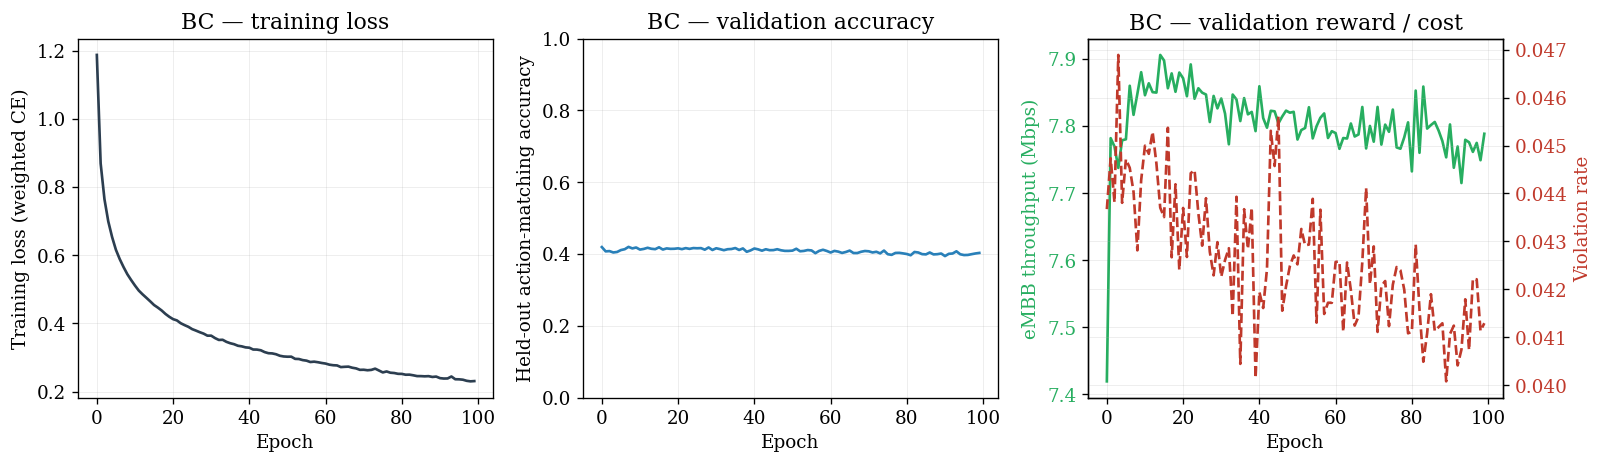

✅ Learning curves BC sauvegardées (fig_bc_learning_curves.png)


In [ ]:
# ==============================================================================
# CELLULE 13-VIZ : LEARNING CURVES BC (loss, accuracy, reward/cost de validation)
# ==============================================================================
import matplotlib.pyplot as plt

PUB_STYLE = {
    'font.size': 11, 'font.family': 'serif', 'axes.linewidth': 0.8,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'legend.framealpha': 0.95, 'savefig.dpi': 300, 'figure.dpi': 120,
}
plt.rcParams.update(PUB_STYLE)
OUT = '/content/drive/MyDrive/openran_dataset/processed/'
ep_ax = bc_history['epoch']

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))

axes[0].plot(ep_ax, bc_history['train_loss'], color='#2c3e50', lw=1.6)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Training loss (weighted CE)')
axes[0].set_title('BC — training loss')

axes[1].plot(ep_ax, bc_history['test_acc'], color='#2980b9', lw=1.6)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Held-out action-matching accuracy')
axes[1].set_ylim(0, 1); axes[1].set_title('BC — validation accuracy')

ax2 = axes[2]
ax2.plot(ep_ax, bc_history['test_reward'], color='#27ae60', lw=1.6, label='eMBB reward (Mbps)')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('eMBB throughput (Mbps)', color='#27ae60')
ax2.tick_params(axis='y', labelcolor='#27ae60')
ax3 = ax2.twinx()
ax3.plot(ep_ax, bc_history['test_cost'], color='#c0392b', lw=1.6, ls='--', label='URLLC violation rate')
ax3.set_ylabel('Violation rate', color='#c0392b')
ax3.tick_params(axis='y', labelcolor='#c0392b')
axes[2].set_title('BC — validation reward / cost')

for ax in axes: ax.grid(alpha=0.25, lw=0.5)
plt.tight_layout()
plt.savefig(OUT+'fig_bc_learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Learning curves BC sauvegardées (fig_bc_learning_curves.png)")

In [ ]:
# ==============================================================================
# CELLULE 14 (VERSION FINALE, ex-14c) : CQL DISCRET (DQN + pénalité conservative) — offline, NON-safe
# γ bas (horizon court) + double-Q + soft target + clip : stabilise la divergence de Bellman
# observée avec γ=0.99 sur ce dataset à action quasi-figée par épisode (versions 14/14b supprimées).
# ==============================================================================
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

d=np.load('/content/drive/MyDrive/openran_dataset/processed/cql_dataset.npz',allow_pickle=True)
S_tr,A_tr,R_tr,C_tr,Sn_tr,D_tr=(d['S_train'],d['A_train'],d['R_train'],d['C_train'],d['Sn_train'],d['D_train'])
S_te,A_te,R_te,C_te,Sn_te,D_te=(d['S_test'],d['A_test'],d['R_test'],d['C_test'],d['Sn_test'],d['D_test'])
SDIM=S_tr.shape[1]; NACT=8; dev='cuda' if torch.cuda.is_available() else 'cpu'
R_MEAN,R_STD=R_tr.mean(),R_tr.std()+1e-8
def rn(r): return (r-R_MEAN)/R_STD

GAMMA=0.7; ALPHA=0.5; TAU=0.01; CLIP=10.0      # γ bas = clé de la stabilité
print(f"{dev} | γ={GAMMA} (horizon court) α={ALPHA}")

class QNet(nn.Module):
    def __init__(s,din,dout,h=256):
        super().__init__(); s.net=nn.Sequential(
            nn.Linear(din,h),nn.ReLU(),nn.Linear(h,h),nn.ReLU(),nn.Linear(h,dout))
    def forward(s,x): return s.net(x)

torch.manual_seed(0)
q1,q2=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
t1,t2=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
t1.load_state_dict(q1.state_dict()); t2.load_state_dict(q2.state_dict())
opt=torch.optim.Adam(list(q1.parameters())+list(q2.parameters()),lr=3e-4)
ds=TensorDataset(torch.tensor(S_tr),torch.tensor(A_tr),torch.tensor(rn(R_tr)),
                 torch.tensor(Sn_tr),torch.tensor(D_tr))
dl=DataLoader(ds,batch_size=1024,shuffle=True)
def soft(tn,qn):
    for tp,p in zip(tn.parameters(),qn.parameters()): tp.data.mul_(1-TAU).add_(TAU*p.data)

EPOCHS_CQL = 100
S_te_t = torch.tensor(S_te).to(dev)
cql_history = {'epoch':[], 'bellman':[], 'cql_penalty':[], 'test_match_acc':[], 'test_reward':[], 'test_cost':[]}
for ep in range(EPOCHS_CQL):
    tb=tc=0
    for s,a,r,sn,done in dl:
        s,a,r,sn,done=[x.to(dev) for x in (s,a,r,sn,done)]; a=a.long()
        with torch.no_grad():
            an=q1(sn).argmax(1,keepdim=True)
            tnext=torch.min(t1(sn).gather(1,an),t2(sn).gather(1,an)).squeeze(1)
            tgt=r+GAMMA*(1-done)*tnext
        for qnet in (q1,q2):
            qsa=qnet(s).gather(1,a.unsqueeze(1)).squeeze(1)
            bell=F.mse_loss(qsa,tgt); cql=(torch.logsumexp(qnet(s),1)-qsa).mean()
            loss=bell+ALPHA*cql
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(qnet.parameters(),CLIP); opt.step()
            tb+=bell.item(); tc+=cql.item()
        soft(t1,q1); soft(t2,q2)

    # métriques de suivi (learning curves) : matching de l'action gloutonne vs dataset, sur le test
    q1.eval()
    with torch.no_grad():
        pi_ep=q1(S_te_t).argmax(1).cpu().numpy()
    m_ep=pi_ep==A_te
    q1.train()
    cql_history['epoch'].append(ep)
    cql_history['bellman'].append(tb/(2*len(dl)))
    cql_history['cql_penalty'].append(tc/(2*len(dl)))
    cql_history['test_match_acc'].append(m_ep.mean())
    cql_history['test_reward'].append(R_te[m_ep].mean() if m_ep.any() else np.nan)
    cql_history['test_cost'].append(C_te[m_ep].mean() if m_ep.any() else np.nan)

    if ep%10==0 or ep==EPOCHS_CQL-1:
        print(f"ep {ep:3d}  bellman={cql_history['bellman'][-1]:.4f}  cql={cql_history['cql_penalty'][-1]:.4f}  match_acc={m_ep.mean():.3f}")

# référence BC dynamique (remplace le "(BC: 7.91/0.044)" figé en dur)
try:
    _bc=np.load('/content/drive/MyDrive/openran_dataset/processed/bc_metrics.npz')
    bc_ref=f"BC: {float(_bc['reward']):.2f}/{float(_bc['cost']):.3f}"
except FileNotFoundError:
    bc_ref="BC: exécuter Cellule 13 d'abord"

q1.eval()
with torch.no_grad():
    pi=q1(S_te_t).argmax(1).cpu().numpy()
m=pi==A_te
cql_reward, cql_cost = R_te[m].mean(), C_te[m].mean()
print(f"\n=== CQL γ={GAMMA} — TEST held-out ===")
print(f"[Matching {m.mean():.1%}] reward={cql_reward:.2f}  cost={cql_cost:.3f}  ({bc_ref})")
print(f"Actions: {np.bincount(pi,minlength=8)}  RR={np.mean(pi%2==0):.2f} PF={np.mean(pi%2==1):.2f} PRB39={np.mean(pi//2==3):.2f}")
torch.save(q1.state_dict(),'/content/drive/MyDrive/openran_dataset/processed/cql_nonsafe.pt')
np.savez('/content/drive/MyDrive/openran_dataset/processed/cql_metrics.npz',
         reward=cql_reward, cost=cql_cost, match_acc=m.mean(),
         epoch=np.array(cql_history['epoch']), bellman=np.array(cql_history['bellman']),
         cql_penalty=np.array(cql_history['cql_penalty']), test_match_acc=np.array(cql_history['test_match_acc']),
         test_reward=np.array(cql_history['test_reward']), test_cost=np.array(cql_history['test_cost']))
print("✅ sauvegardé (cql_nonsafe.pt + cql_metrics.npz)")

cuda | γ=0.7 (horizon court) α=0.5
ep   0  bellman=0.1418  cql=1.7208  match_acc=0.357
ep  10  bellman=0.1705  cql=0.9756  match_acc=0.420
ep  20  bellman=0.1651  cql=0.8478  match_acc=0.414
ep  30  bellman=0.1781  cql=0.7678  match_acc=0.406
ep  40  bellman=0.1659  cql=0.7093  match_acc=0.419
ep  50  bellman=0.1638  cql=0.6673  match_acc=0.411
ep  60  bellman=0.1582  cql=0.6355  match_acc=0.411
ep  70  bellman=0.1561  cql=0.6082  match_acc=0.412
ep  80  bellman=0.1530  cql=0.5854  match_acc=0.408
ep  90  bellman=0.1502  cql=0.5646  match_acc=0.408
ep  99  bellman=0.1483  cql=0.5491  match_acc=0.414

=== CQL γ=0.7 — TEST held-out ===
[Matching 41.4%] reward=7.74  cost=0.040  (BC: 7.79/0.041)
Actions: [ 5955  5982 12244  4433  9165  6795  8039  8740]  RR=0.58 PF=0.42 PRB39=0.27
✅ sauvegardé (cql_nonsafe.pt + cql_metrics.npz)


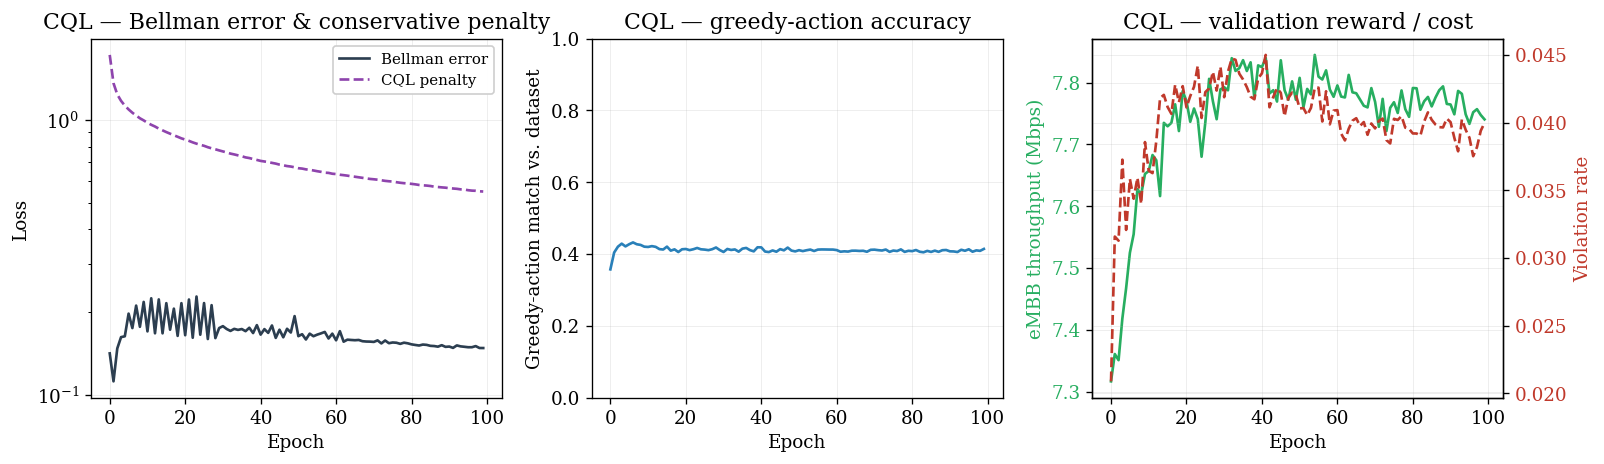

✅ Learning curves CQL sauvegardées (fig_cql_learning_curves.png)


In [ ]:
# ==============================================================================
# CELLULE 14-VIZ : LEARNING CURVES CQL (Bellman, pénalité CQL, accuracy, reward/cost)
# ==============================================================================
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 11, 'font.family': 'serif', 'axes.linewidth': 0.8,
                      'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
                      'legend.framealpha': 0.95, 'savefig.dpi': 300, 'figure.dpi': 120})
OUT = '/content/drive/MyDrive/openran_dataset/processed/'
ep_ax = cql_history['epoch']

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))

axes[0].plot(ep_ax, cql_history['bellman'], color='#2c3e50', lw=1.6, label='Bellman error')
axes[0].plot(ep_ax, cql_history['cql_penalty'], color='#8e44ad', lw=1.6, ls='--', label='CQL penalty')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].set_yscale('log')
axes[0].legend(fontsize=9); axes[0].set_title('CQL — Bellman error & conservative penalty')

axes[1].plot(ep_ax, cql_history['test_match_acc'], color='#2980b9', lw=1.6)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Greedy-action match vs. dataset')
axes[1].set_ylim(0, 1); axes[1].set_title('CQL — greedy-action accuracy')

ax2 = axes[2]
ax2.plot(ep_ax, cql_history['test_reward'], color='#27ae60', lw=1.6)
ax2.set_xlabel('Epoch'); ax2.set_ylabel('eMBB throughput (Mbps)', color='#27ae60')
ax2.tick_params(axis='y', labelcolor='#27ae60')
ax3 = ax2.twinx()
ax3.plot(ep_ax, cql_history['test_cost'], color='#c0392b', lw=1.6, ls='--')
ax3.set_ylabel('Violation rate', color='#c0392b')
ax3.tick_params(axis='y', labelcolor='#c0392b')
axes[2].set_title('CQL — validation reward / cost')

for ax in axes: ax.grid(alpha=0.25, lw=0.5)
plt.tight_layout()
plt.savefig(OUT+'fig_cql_learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Learning curves CQL sauvegardées (fig_cql_learning_curves.png)")

In [ ]:
# ==============================================================================
# CELLULE 15 (VERSION FINALE, ex-15d) : CQL-LAGRANGIAN (SAFE) — cœur du papier
# Coût tabulé empirique (par action × bin de charge), plus robuste que le réseau Q_cost
# des versions 15/15b (λ inopérant / séparation RR-PF incertaine — cf. diagnostic 15c, supprimé).
# Politique : argmax_a [ Q_reward(s,a) − λ · cost_table[a, bin(s)] ]
# ==============================================================================
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

d=np.load('/content/drive/MyDrive/openran_dataset/processed/cql_dataset.npz',allow_pickle=True)
S_tr,A_tr,R_tr,C_tr,Sn_tr,D_tr=(d['S_train'],d['A_train'],d['R_train'],d['C_train'],d['Sn_train'],d['D_train'])
S_te,A_te,R_te,C_te,Sn_te,D_te=(d['S_test'],d['A_test'],d['R_test'],d['C_test'],d['Sn_test'],d['D_test'])
state_cols=list(d['state_cols']); mu=d['mu']; std=d['std']
SDIM=S_tr.shape[1]; NACT=8; dev='cuda' if torch.cuda.is_available() else 'cpu'
R_MEAN,R_STD=R_tr.mean(),R_tr.std()+1e-8
def rn(r): return (r-R_MEAN)/R_STD

# --- COÛT TABULÉ : par action × bin de charge (nof_ue) ---
# nof_ue est normalisé dans S ; on le dé-normalise pour binner
nof_idx=state_cols.index('nof_ue')
nof_tr=S_tr[:,nof_idx]*std[nof_idx]+mu[nof_idx]
bins=np.array([0,3.5,5.5,8.1])             # faible / moyenne / forte charge
bin_tr=np.clip(np.digitize(nof_tr,bins)-1,0,len(bins)-2)
NBIN=len(bins)-1

cost_table=np.full((NACT,NBIN),np.nan)
for a in range(NACT):
    for b in range(NBIN):
        mask=(A_tr==a)&(bin_tr==b)
        if mask.sum()>20: cost_table[a,b]=C_tr[mask].mean()
# combler les cases vides par le coût global de l'action
for a in range(NACT):
    ga=C_tr[A_tr==a].mean()
    for b in range(NBIN):
        if np.isnan(cost_table[a,b]): cost_table[a,b]=ga
print("=== COÛT TABULÉ (action × charge) ===")
print("           charge:  faible  moyenne  forte")
names=['(9,RR)','(9,PF)','(21,RR)','(21,PF)','(30,RR)','(30,PF)','(39,RR)','(39,PF)']
for a in range(NACT):
    print(f"  a{a} {names[a]:8s}  "+"  ".join(f"{cost_table[a,b]:.3f}" for b in range(NBIN)))
cost_table_t=torch.tensor(cost_table,dtype=torch.float32,device=dev)

# --- Q_reward : on réutilise l'entraînement stable (γ=0.7) ---
class QNet(nn.Module):
    def __init__(s,din,dout,h=256):
        super().__init__(); s.net=nn.Sequential(
            nn.Linear(din,h),nn.ReLU(),nn.Linear(h,h),nn.ReLU(),nn.Linear(h,dout))
    def forward(s,x): return s.net(x)
GAMMA=0.7; ALPHA=0.5; TAU=0.01; CLIP=10.0
torch.manual_seed(0)
q1,q2=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
t1,t2=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
t1.load_state_dict(q1.state_dict()); t2.load_state_dict(q2.state_dict())
opt=torch.optim.Adam(list(q1.parameters())+list(q2.parameters()),lr=3e-4)

bin_tr_t=torch.tensor(bin_tr,device=dev)
ds=TensorDataset(torch.tensor(S_tr),torch.tensor(A_tr),torch.tensor(rn(R_tr)),
                 torch.tensor(Sn_tr),torch.tensor(D_tr),
                 torch.arange(len(S_tr)))   # index pour retrouver le bin
dl=DataLoader(ds,batch_size=1024,shuffle=True)
def soft(tn,qn):
    for tp,p in zip(tn.parameters(),qn.parameters()): tp.data.mul_(1-TAU).add_(TAU*p.data)

# politique safe : argmax(Q_r - λ·cost_table[a,bin])
def policy(S_np, bins_np, lam):
    with torch.no_grad():
        S_t=torch.tensor(S_np).to(dev)
        qr=torch.min(q1(S_t),q2(S_t))                       # (N,8)
        ct=cost_table_t[:,torch.tensor(bins_np,device=dev)].T  # (N,8)
        return (qr - lam*ct).argmax(1).cpu().numpy()

# Q_reward greedy pour le bootstrap (politique courante avec λ courant)
EPOCHS_SAFE = 100
BUDGET=0.03; LR_LAMBDA=5.0; log_lambda=torch.tensor(-1.0)
nof_te=S_te[:,nof_idx]*std[nof_idx]+mu[nof_idx]
bin_te=np.clip(np.digitize(nof_te,bins)-1,0,NBIN-1)
safe_history = {'epoch':[], 'bellman':[], 'lambda':[], 'cost_pi_train':[],
                'test_match_acc':[], 'test_reward':[], 'test_cost':[]}
for ep in range(EPOCHS_SAFE):
    lam=float(torch.exp(log_lambda)); tb=0
    for s,a,r,sn,done,idx in dl:
        s,a,r,sn,done=[x.to(dev) for x in (s,a,r,sn,done)]; a=a.long()
        b_next=bin_tr_t[idx.to(dev)]                         # approx: bin stable dans l'épisode
        with torch.no_grad():
            qr_n=torch.min(t1(sn),t2(sn))
            ct_n=cost_table_t[:,b_next].T
            an=(qr_n-lam*ct_n).argmax(1,keepdim=True)
            tgt=r+GAMMA*(1-done)*torch.min(t1(sn).gather(1,an),t2(sn).gather(1,an)).squeeze(1)
        for qnet in (q1,q2):
            qsa=qnet(s).gather(1,a.unsqueeze(1)).squeeze(1)
            l=F.mse_loss(qsa,tgt)+ALPHA*(torch.logsumexp(qnet(s),1)-qsa).mean()
            opt.zero_grad(); l.backward(); nn.utils.clip_grad_norm_(qnet.parameters(),CLIP); opt.step(); tb+=l.item()
        soft(t1,q1); soft(t2,q2)
    # λ update sur coût réel tabulé de la politique
    pi_tr=policy(S_tr,bin_tr,lam)
    cost_pi=cost_table[pi_tr,bin_tr].mean()
    log_lambda += LR_LAMBDA*(cost_pi-BUDGET); log_lambda.clamp_(-5,5)

    # métriques de suivi (learning curves), sur le test held-out
    pi_ep=policy(S_te,bin_te,lam); m_ep=pi_ep==A_te
    safe_history['epoch'].append(ep)
    safe_history['bellman'].append(tb/(2*len(dl)))
    safe_history['lambda'].append(lam)
    safe_history['cost_pi_train'].append(cost_pi)
    safe_history['test_match_acc'].append(m_ep.mean())
    safe_history['test_reward'].append(R_te[m_ep].mean() if m_ep.any() else np.nan)
    safe_history['test_cost'].append(C_te[m_ep].mean() if m_ep.any() else np.nan)

    if ep%10==0 or ep==EPOCHS_SAFE-1:
        print(f"ep {ep:3d} bell={safe_history['bellman'][-1]:.3f} λ={float(torch.exp(log_lambda)):.3f} cost_π={cost_pi:.3f}")

# === ÉVAL FINALE ===
lam=float(torch.exp(log_lambda))
pi=policy(S_te,bin_te,lam); m=pi==A_te
safe_reward, safe_cost = R_te[m].mean(), C_te[m].mean()

# références BC / CQL dynamiques (remplace les chiffres "7.91/0.044" et "7.73/0.042" figés en dur)
def _load_ref(path, default):
    try: return np.load(path)
    except FileNotFoundError: return default
_bc=_load_ref('/content/drive/MyDrive/openran_dataset/processed/bc_metrics.npz', None)
_cql=_load_ref('/content/drive/MyDrive/openran_dataset/processed/cql_metrics.npz', None)
bc_line = f"  BC        reward={float(_bc['reward']):.2f} cost={float(_bc['cost']):.3f}" if _bc is not None else "  BC        (exécuter Cellule 13 d'abord)"
cql_line = f"  CQL       reward={float(_cql['reward']):.2f} cost={float(_cql['cost']):.3f}" if _cql is not None else "  CQL       (exécuter Cellule 14 d'abord)"

print(f"\n=== CQL-SAFE (coût tabulé) — TEST (λ={lam:.2f}) ===")
print(f"[Matching {m.mean():.1%}] reward={safe_reward:.2f} cost={safe_cost:.3f}")
print(f"RR={np.mean(pi%2==0):.2f} PF={np.mean(pi%2==1):.2f} PRB39={np.mean(pi//2==3):.2f}")
print(f"\n=== 3 AGENTS (test held-out) ===")
print(bc_line)
print(cql_line)
print(f"  CQL-safe  reward={safe_reward:.2f} cost={safe_cost:.3f} RR={np.mean(pi%2==0):.2f}")

# sauvegarde du modèle Safe-CQL final (manquait dans la version précédente : q1/q2 + cost_table + λ)
torch.save({'q1':q1.state_dict(),'q2':q2.state_dict(),
            'cost_table':cost_table,'bins':bins,'lambda':lam},
           '/content/drive/MyDrive/openran_dataset/processed/cql_safe.pt')
np.savez('/content/drive/MyDrive/openran_dataset/processed/safe_metrics.npz',
         reward=safe_reward, cost=safe_cost, lam=lam,
         epoch=np.array(safe_history['epoch']), bellman=np.array(safe_history['bellman']),
         lam_history=np.array(safe_history['lambda']), cost_pi_train=np.array(safe_history['cost_pi_train']),
         test_match_acc=np.array(safe_history['test_match_acc']),
         test_reward=np.array(safe_history['test_reward']), test_cost=np.array(safe_history['test_cost']))
print("✅ Safe-CQL sauvegardé (cql_safe.pt + safe_metrics.npz)")

=== COÛT TABULÉ (action × charge) ===
           charge:  faible  moyenne  forte
  a0 (9,RR)    0.001  0.002  0.033
  a1 (9,PF)    0.014  0.101  0.289
  a2 (21,RR)   0.005  0.007  0.029
  a3 (21,PF)   0.041  0.044  0.224
  a4 (30,RR)   0.147  0.030  0.037
  a5 (30,PF)   0.030  0.073  0.244
  a6 (39,RR)   0.057  0.035  0.025
  a7 (39,PF)   0.050  0.058  0.212
ep   0 bell=0.992 λ=0.369 cost_π=0.031
ep  10 bell=0.649 λ=0.593 cost_π=0.042
ep  20 bell=0.592 λ=1.171 cost_π=0.044
ep  30 bell=0.558 λ=2.203 cost_π=0.041
ep  40 bell=0.516 λ=3.705 cost_π=0.039
ep  50 bell=0.502 λ=5.348 cost_π=0.036
ep  60 bell=0.489 λ=6.931 cost_π=0.035
ep  70 bell=0.477 λ=8.498 cost_π=0.034
ep  80 bell=0.467 λ=9.901 cost_π=0.033
ep  90 bell=0.461 λ=11.121 cost_π=0.032
ep  99 bell=0.456 λ=12.223 cost_π=0.032

=== CQL-SAFE (coût tabulé) — TEST (λ=12.22) ===
[Matching 38.7%] reward=7.70 cost=0.030
RR=0.74 PF=0.26 PRB39=0.27

=== 3 AGENTS (test held-out) ===
  BC        reward=7.79 cost=0.041
  CQL       reward=7.74

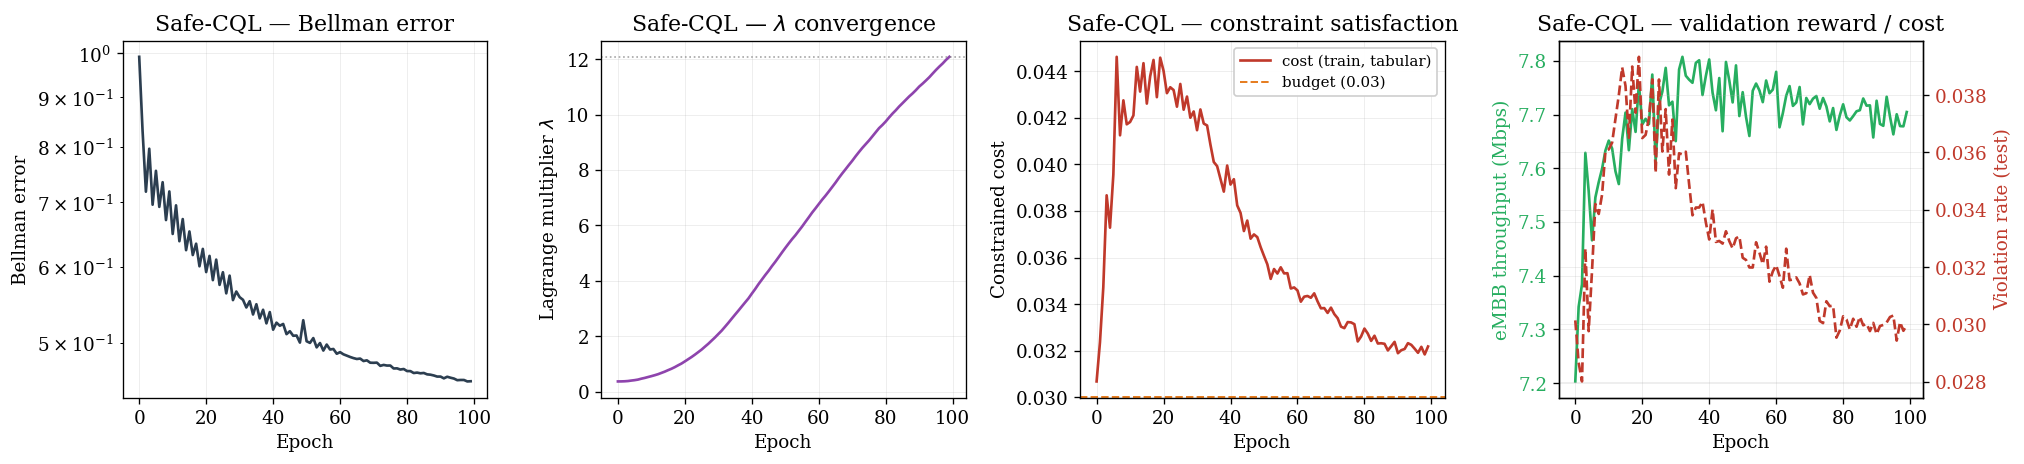

✅ Learning curves Safe-CQL sauvegardées (fig_safecql_learning_curves.png)


In [ ]:
# ==============================================================================
# CELLULE 15-VIZ : LEARNING CURVES SAFE-CQL (Bellman, λ, coût contraint, reward/cost)
# ==============================================================================
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 11, 'font.family': 'serif', 'axes.linewidth': 0.8,
                      'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
                      'legend.framealpha': 0.95, 'savefig.dpi': 300, 'figure.dpi': 120})
OUT = '/content/drive/MyDrive/openran_dataset/processed/'
ep_ax = safe_history['epoch']

fig, axes = plt.subplots(1, 4, figsize=(17, 4))

axes[0].plot(ep_ax, safe_history['bellman'], color='#2c3e50', lw=1.6)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Bellman error'); axes[0].set_yscale('log')
axes[0].set_title('Safe-CQL — Bellman error')

axes[1].plot(ep_ax, safe_history['lambda'], color='#8e44ad', lw=1.6)
axes[1].axhline(safe_history['lambda'][-1], ls=':', color='gray', lw=1, alpha=0.7)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel(r'Lagrange multiplier $\lambda$')
axes[1].set_title(r'Safe-CQL — $\lambda$ convergence')

axes[2].plot(ep_ax, safe_history['cost_pi_train'], color='#c0392b', lw=1.6, label='cost (train, tabular)')
axes[2].axhline(BUDGET, ls='--', color='#e67e22', lw=1.2, label=f'budget ({BUDGET})')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Constrained cost'); axes[2].legend(fontsize=9)
axes[2].set_title('Safe-CQL — constraint satisfaction')

ax3 = axes[3]
ax3.plot(ep_ax, safe_history['test_reward'], color='#27ae60', lw=1.6)
ax3.set_xlabel('Epoch'); ax3.set_ylabel('eMBB throughput (Mbps)', color='#27ae60')
ax3.tick_params(axis='y', labelcolor='#27ae60')
ax4 = ax3.twinx()
ax4.plot(ep_ax, safe_history['test_cost'], color='#c0392b', lw=1.6, ls='--')
ax4.set_ylabel('Violation rate (test)', color='#c0392b')
ax4.tick_params(axis='y', labelcolor='#c0392b')
axes[3].set_title('Safe-CQL — validation reward / cost')

for ax in axes: ax.grid(alpha=0.25, lw=0.5)
plt.tight_layout()
plt.savefig(OUT+'fig_safecql_learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Learning curves Safe-CQL sauvegardées (fig_safecql_learning_curves.png)")

In [ ]:
# ==============================================================================
# CELLULE 20 : FQE — confirmation du classement par 2e méthode d'évaluation
# Estime V_reward et V_cost de chaque politique sur TOUS les états test
# (pas seulement les matchs). CQL : 4 seeds. Safe-CQL : le VRAI agent contraint de la Cellule 15
# (même algorithme, coût 3-tranches, λ appris), ré-entraîné sur 2 seeds. Compare au matching.
# ==============================================================================
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

d=np.load('/content/drive/MyDrive/openran_dataset/processed/cql_dataset.npz',allow_pickle=True)
S_tr,A_tr,R_tr,C_tr,Sn_tr,D_tr=(d['S_train'],d['A_train'],d['R_train'],d['C_train'],d['Sn_train'],d['D_train'])
S_te,A_te,R_te,C_te=(d['S_test'],d['A_test'],d['R_test'],d['C_test'])
state_cols=list(d['state_cols']); mu=d['mu']; std=d['std']
SDIM=S_tr.shape[1]; NACT=8; dev='cuda' if torch.cuda.is_available() else 'cpu'
R_MEAN,R_STD=R_tr.mean(),R_tr.std()+1e-8
def rn(r): return (r-R_MEAN)/R_STD
GAMMA=0.7;ALPHA=0.5;TAU=0.01;CLIP=10.0

# coût tabulé (pour les politiques cost-aware sur train ET test)
nof_idx=state_cols.index('nof_ue')
def get_bins(S):
    nv=S[:,nof_idx]*std[nof_idx]+mu[nof_idx]
    return np.clip(np.digitize(nv,np.array([0,2.5,4.5,6.5,8.1]))-1,0,3)
bin_tr=get_bins(S_tr); bin_te=get_bins(S_te); NBIN=4
cost_table=np.zeros((NACT,NBIN))
for a in range(NACT):
    ga=C_tr[A_tr==a].mean()
    for b in range(NBIN):
        mk=(A_tr==a)&(bin_tr==b); cost_table[a,b]=C_tr[mk].mean() if mk.sum()>50 else ga
ct_tr=torch.tensor(cost_table[:,bin_tr].T,dtype=torch.float32,device=dev)  # (Ntr,8)
ct_te_np=cost_table[:,bin_te].T

# --- coût tabulé "safe" : MÊME binning que la Cellule 15 (3 tranches), pour rester fidèle
# à l'agent réellement entraîné sous contrainte (au contraire du coût 4-tranches ci-dessus,
# utilisé uniquement pour CQL où lam=0 annule ce terme et rend le binning sans effet) ---
bins_safe=np.array([0,3.5,5.5,8.1]); NBIN_SAFE=len(bins_safe)-1
def get_bins_safe(S):
    nv=S[:,nof_idx]*std[nof_idx]+mu[nof_idx]
    return np.clip(np.digitize(nv,bins_safe)-1,0,NBIN_SAFE-1)
bin_tr_safe=get_bins_safe(S_tr); bin_te_safe=get_bins_safe(S_te)
cost_table_safe=np.full((NACT,NBIN_SAFE),np.nan)
for a in range(NACT):
    for b in range(NBIN_SAFE):
        mask=(A_tr==a)&(bin_tr_safe==b)
        if mask.sum()>20: cost_table_safe[a,b]=C_tr[mask].mean()
for a in range(NACT):
    ga=C_tr[A_tr==a].mean()
    for b in range(NBIN_SAFE):
        if np.isnan(cost_table_safe[a,b]): cost_table_safe[a,b]=ga
cost_table_safe_t=torch.tensor(cost_table_safe,dtype=torch.float32,device=dev)
ct_tr_safe=torch.tensor(cost_table_safe[:,bin_tr_safe].T,dtype=torch.float32,device=dev)
ct_te_safe_np=cost_table_safe[:,bin_te_safe].T
bin_tr_safe_t=torch.tensor(bin_tr_safe,device=dev)

class QNet(nn.Module):
    def __init__(s,din,dout,h=256):
        super().__init__(); s.net=nn.Sequential(nn.Linear(din,h),nn.ReLU(),nn.Linear(h,h),nn.ReLU(),nn.Linear(h,dout))
    def forward(s,x): return s.net(x)

def train_qreward(seed):
    torch.manual_seed(seed)
    q1,q2=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
    t1,t2=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
    t1.load_state_dict(q1.state_dict());t2.load_state_dict(q2.state_dict())
    opt=torch.optim.Adam(list(q1.parameters())+list(q2.parameters()),lr=3e-4)
    ds=TensorDataset(torch.tensor(S_tr),torch.tensor(A_tr),torch.tensor(rn(R_tr)),torch.tensor(Sn_tr),torch.tensor(D_tr))
    dl=DataLoader(ds,batch_size=1024,shuffle=True)
    def soft(tn,qn):
        for tp,p in zip(tn.parameters(),qn.parameters()): tp.data.mul_(1-TAU).add_(TAU*p.data)
    for ep in range(100):
        for s,a,r,sn,done in dl:
            s,a,r,sn,done=[x.to(dev) for x in (s,a,r,sn,done)];a=a.long()
            with torch.no_grad():
                an=q1(sn).argmax(1,keepdim=True)
                tgt=r+GAMMA*(1-done)*torch.min(t1(sn).gather(1,an),t2(sn).gather(1,an)).squeeze(1)
            for qn in (q1,q2):
                qsa=qn(s).gather(1,a.unsqueeze(1)).squeeze(1)
                l=F.mse_loss(qsa,tgt)+ALPHA*(torch.logsumexp(qn(s),1)-qsa).mean()
                opt.zero_grad();l.backward();nn.utils.clip_grad_norm_(qn.parameters(),CLIP);opt.step()
            soft(t1,q1);soft(t2,q2)
    q1.eval();q2.eval()
    with torch.no_grad():
        Qr_tr=torch.min(q1(torch.tensor(S_tr).to(dev)),q2(torch.tensor(S_tr).to(dev)))
        Qr_te=torch.min(q1(torch.tensor(S_te).to(dev)),q2(torch.tensor(S_te).to(dev)))
    return Qr_tr, Qr_te

def train_safecql(seed):
    """Reproduit EXACTEMENT l'algorithme de la Cellule 15 (CQL-Lagrangian, coût tabulé 3-tranches,
    BUDGET=0.03, λ appris par ascension duale) — paramétré par seed pour obtenir un intervalle de
    confiance sur le VRAI agent contraint, au lieu du CQL non-contraint + λ=8 fixé a posteriori
    utilisé dans une version antérieure de cette cellule."""
    torch.manual_seed(seed)
    q1s,q2s=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
    t1s,t2s=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
    t1s.load_state_dict(q1s.state_dict()); t2s.load_state_dict(q2s.state_dict())
    opt_s=torch.optim.Adam(list(q1s.parameters())+list(q2s.parameters()),lr=3e-4)
    ds_s=TensorDataset(torch.tensor(S_tr),torch.tensor(A_tr),torch.tensor(rn(R_tr)),
                        torch.tensor(Sn_tr),torch.tensor(D_tr),torch.arange(len(S_tr)))
    dl_s=DataLoader(ds_s,batch_size=1024,shuffle=True)
    def soft_s(tn,qn):
        for tp,p in zip(tn.parameters(),qn.parameters()): tp.data.mul_(1-TAU).add_(TAU*p.data)
    def policy_s(S_np,bins_np,lam):
        with torch.no_grad():
            S_t=torch.tensor(S_np).to(dev)
            qr=torch.min(q1s(S_t),q2s(S_t))
            ct=cost_table_safe_t[:,torch.tensor(bins_np,device=dev)].T
            return (qr-lam*ct).argmax(1).cpu().numpy()

    BUDGET_S=0.03; LR_LAMBDA_S=5.0; log_lambda_s=torch.tensor(-1.0)
    for ep in range(100):
        lam_s=float(torch.exp(log_lambda_s))
        for s,a,r,sn,done,idx in dl_s:
            s,a,r,sn,done=[x.to(dev) for x in (s,a,r,sn,done)]; a=a.long()
            b_next=bin_tr_safe_t[idx.to(dev)]
            with torch.no_grad():
                qr_n=torch.min(t1s(sn),t2s(sn))
                ct_n=cost_table_safe_t[:,b_next].T
                an=(qr_n-lam_s*ct_n).argmax(1,keepdim=True)
                tgt=r+GAMMA*(1-done)*torch.min(t1s(sn).gather(1,an),t2s(sn).gather(1,an)).squeeze(1)
            for qnet in (q1s,q2s):
                qsa=qnet(s).gather(1,a.unsqueeze(1)).squeeze(1)
                l=F.mse_loss(qsa,tgt)+ALPHA*(torch.logsumexp(qnet(s),1)-qsa).mean()
                opt_s.zero_grad(); l.backward(); nn.utils.clip_grad_norm_(qnet.parameters(),CLIP); opt_s.step()
            soft_s(t1s,q1s); soft_s(t2s,q2s)
        pi_tr_s=policy_s(S_tr,bin_tr_safe,lam_s)
        cost_pi_s=cost_table_safe[pi_tr_s,bin_tr_safe].mean()
        log_lambda_s += LR_LAMBDA_S*(cost_pi_s-BUDGET_S); log_lambda_s.clamp_(-5,5)

    lam_final=float(torch.exp(log_lambda_s))
    q1s.eval(); q2s.eval()
    with torch.no_grad():
        Qr_te_safe=torch.min(q1s(torch.tensor(S_te).to(dev)),q2s(torch.tensor(S_te).to(dev)))
    return Qr_te_safe, lam_final

def fqe(Qr_te, lam, ct_tr_arg, ct_te_arg, seed):
    """Évalue par FQE la politique argmax(Qr - lam*cost) où Qr_te/ct_tr_arg/ct_te_arg viennent du
    modèle réellement entraîné qu'on passe en argument (CQL non-contraint avec lam=0, où le coût
    n'a aucun effet ; ou Safe-CQL avec son propre Qr, son λ convergé et son coût 3-tranches)."""
    torch.manual_seed(seed+50)
    qe_r=QNet(SDIM,NACT).to(dev); qe_c=QNet(SDIM,NACT).to(dev)
    oe=torch.optim.Adam(list(qe_r.parameters())+list(qe_c.parameters()),lr=3e-4)
    ds=TensorDataset(torch.tensor(S_tr),torch.tensor(A_tr),torch.tensor(R_tr),
                     torch.tensor(C_tr),torch.tensor(Sn_tr),torch.tensor(D_tr),
                     torch.arange(len(S_tr)))
    dl=DataLoader(ds,batch_size=1024,shuffle=True)
    for ep in range(6):
        for s,a,r,c,sn,done,idx in dl:
            s,a,r,c,sn,done,idx=[x.to(dev) for x in (s,a,r,c,sn,done,idx)];a=a.long()
            with torch.no_grad():
                an=(qe_r(sn)-lam*ct_tr_arg[idx]).argmax(1,keepdim=True)
                tr=r+GAMMA*(1-done)*qe_r(sn).gather(1,an).squeeze(1)
                tc=c+GAMMA*(1-done)*qe_c(sn).gather(1,an).squeeze(1)
            lr_=F.mse_loss(qe_r(s).gather(1,a.unsqueeze(1)).squeeze(1),tr)
            lc_=F.mse_loss(qe_c(s).gather(1,a.unsqueeze(1)).squeeze(1),tc)
            oe.zero_grad();(lr_+lc_).backward();oe.step()
    with torch.no_grad():
        a_te=(Qr_te-lam*torch.tensor(ct_te_arg,device=dev)).argmax(1)
        v_r=qe_r(torch.tensor(S_te).to(dev)).gather(1,a_te.unsqueeze(1)).mean().item()
        v_c=qe_c(torch.tensor(S_te).to(dev)).gather(1,a_te.unsqueeze(1)).mean().item()
    return v_r, v_c

# --- CQL (λ=0) : coût sans effet (lam=0), le binning 4-tranches ci-dessus ne joue donc aucun rôle ---
SEEDS=[0,1,2,3]
agg={'cql':{'r':[],'c':[]}, 'safe':{'r':[],'c':[],'lam':[]}}
for seed in SEEDS:
    _,Qr_te=train_qreward(seed)
    vr,vc=fqe(Qr_te,0,ct_tr,ct_te_np,seed)
    agg['cql']['r'].append(vr); agg['cql']['c'].append(vc)
    print(f"seed {seed} ok (CQL)")

# --- Safe-CQL : on ré-entraîne le VRAI agent contraint (algorithme de la Cellule 15, coût
# 3-tranches, λ appris) sur 2 seeds indépendantes, pour un intervalle de confiance cohérent avec
# ce que la Cellule 15 a réellement appris — remplace l'ancien CQL+pénalité λ=8 post-hoc. ---
SEEDS_SAFE=[0,1]
for seed in SEEDS_SAFE:
    Qr_te_safe,lam_safe=train_safecql(seed)
    vr,vc=fqe(Qr_te_safe,lam_safe,ct_tr_safe,ct_te_safe_np,seed)
    agg['safe']['r'].append(vr); agg['safe']['c'].append(vc); agg['safe']['lam'].append(lam_safe)
    print(f"seed {seed} ok (Safe-CQL, λ={lam_safe:.2f})")

print("\n=== FQE (valeur estimée, tous états test) ===")
print(f"{'Agent':26s} {'V_reward(Mbps)':>16s} {'V_cost':>14s}")
r=np.array(agg['cql']['r']); c=np.array(agg['cql']['c'])
print(f"{'CQL (λ=0), 4 seeds':26s} {f'{r.mean():.2f} ± {r.std():.2f}':>16s} {f'{c.mean():.3f} ± {c.std():.3f}':>14s}")
r=np.array(agg['safe']['r']); c=np.array(agg['safe']['c']); lams=np.array(agg['safe']['lam'])
print(f"{'CQL-safe, 2 seeds':26s} {f'{r.mean():.2f} ± {r.std():.2f}':>16s} {f'{c.mean():.3f} ± {c.std():.3f}':>14s}  (λ appris = {lams.mean():.2f}±{lams.std():.2f})")
print("\n>>> CQL-safe doit avoir V_cost < CQL (confirme le matching).")
print(">>> Si FQE et matching concordent sur le classement → résultat robuste à 2 méthodes.")

seed 0 ok (CQL)
seed 1 ok (CQL)
seed 2 ok (CQL)
seed 3 ok (CQL)
seed 0 ok (Safe-CQL, λ=12.22)
seed 1 ok (Safe-CQL, λ=13.51)

=== FQE (valeur estimée, tous états test) ===
Agent                        V_reward(Mbps)         V_cost
CQL (λ=0), 4 seeds             26.63 ± 0.18  0.088 ± 0.020
CQL-safe, 2 seeds              26.17 ± 0.04  0.076 ± 0.005  (λ appris = 12.86±0.64)

>>> CQL-safe doit avoir V_cost < CQL (confirme le matching).
>>> Si FQE et matching concordent sur le classement → résultat robuste à 2 méthodes.


seed 0 ok
seed 1 ok
seed 2 ok
seed 3 ok
seed 4 ok
seed 0 ok (Safe-CQL, λ=12.22)
seed 1 ok (Safe-CQL, λ=13.51)


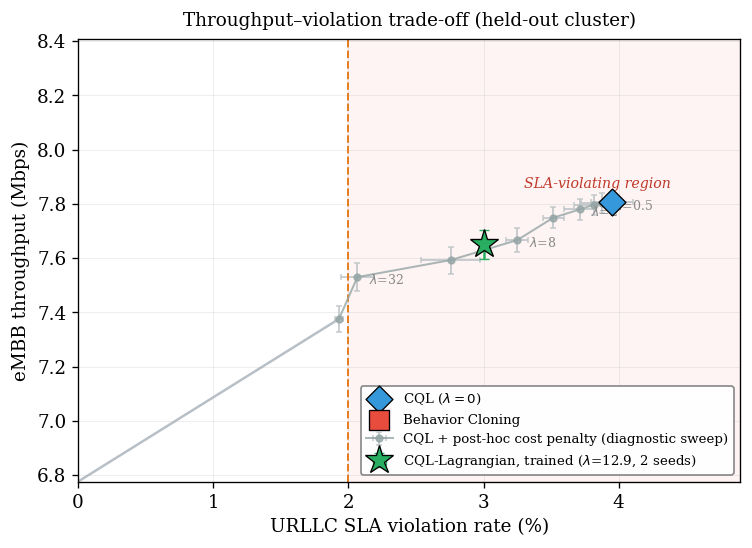

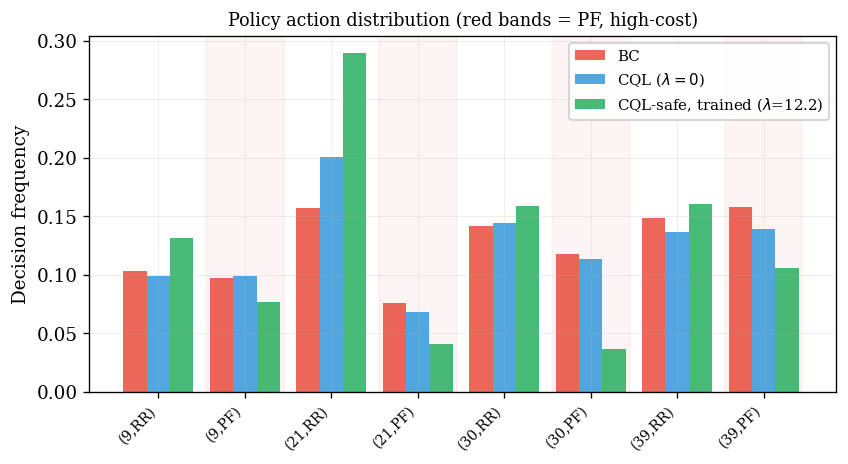

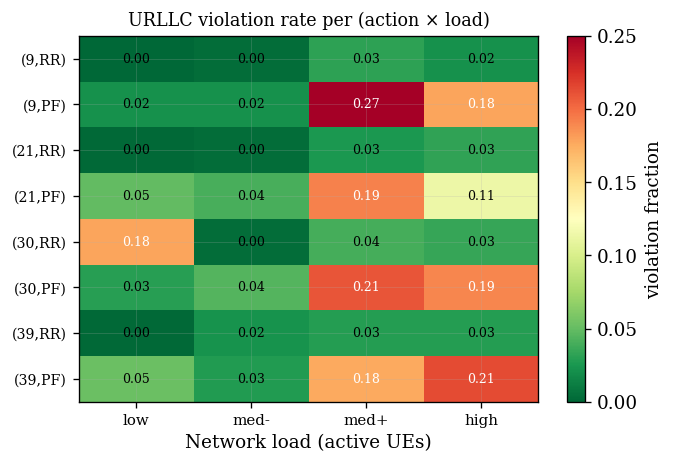


TABLEAU LaTeX :
\begin{table}[t]
\centering
\caption{Offline safe RL benchmark on the held-out cluster (BC/CQL: mean$\pm$std over 5 seeds;
CQL-Lagrangian: mean$\pm$std over 2 seeds, trained end-to-end under the SLA cost constraint, $\lambda$=12.9$\pm$0.6).
Cost = fraction of URLLC packets violating the 20\,ms SLA. Lower cost is safer.}
\label{tab:results}
\begin{tabular}{lcccc}
\toprule
& \multicolumn{2}{c}{Matching OPE} & \multicolumn{2}{c}{Tabular OPE} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}
Method & Thr.\,(Mbps) & Cost & Thr.\,(Mbps) & Cost \\
\midrule
BC (imitation)        & 7.76$\pm$0.10 & 0.041$\pm$0.002 & 7.49$\pm$0.05 & 0.057$\pm$0.002 \\
CQL ($\lambda{=}0$)   & 7.81$\pm$0.04 & 0.040$\pm$0.002 & 7.40$\pm$0.03 & 0.049$\pm$0.002 \\
\textbf{CQL-Lagrangian (safe, trained)} & \textbf{7.65$\pm$0.05} & \textbf{0.030$\pm$0.000} & \textbf{7.31$\pm$0.05} & \textbf{0.030$\pm$0.001} \\
\bottomrule
\end{tabular}
\end{table}

✅ 3 figures + tableau LaTeX sauvegardés dans /content/drive/MyDri

In [ ]:
# ==============================================================================
# CELLULE 21 : LIVRABLES FINAUX — 3 figures multi-seeds + tableau LaTeX
# BC/CQL recalculés sur 5 seeds. Safe-CQL : le VRAI agent contraint de la Cellule 15 (même algorithme,
# coût 3-tranches, λ appris par ascension duale), ré-entraîné sur 2 seeds pour un intervalle de confiance
# — remplace l'ancien "CQL + pénalité λ=8 post-hoc" qui n'évaluait pas le modèle réellement entraîné.
# ==============================================================================
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

d=np.load('/content/drive/MyDrive/openran_dataset/processed/cql_dataset.npz',allow_pickle=True)
S_tr,A_tr,R_tr,C_tr,Sn_tr,D_tr=(d['S_train'],d['A_train'],d['R_train'],d['C_train'],d['Sn_train'],d['D_train'])
S_te,A_te,R_te,C_te=(d['S_test'],d['A_test'],d['R_test'],d['C_test'])
state_cols=list(d['state_cols']); mu=d['mu']; std=d['std']
SDIM=S_tr.shape[1]; NACT=8; dev='cuda' if torch.cuda.is_available() else 'cpu'
R_MEAN,R_STD=R_tr.mean(),R_tr.std()+1e-8
def rn(r): return (r-R_MEAN)/R_STD
GAMMA=0.7;ALPHA=0.5;TAU=0.01;CLIP=10.0
OUT='/content/drive/MyDrive/openran_dataset/processed/'

# --- tables empiriques (reward & cost par action×bin) ---
nof_idx=state_cols.index('nof_ue')
def get_bins(S):
    nv=S[:,nof_idx]*std[nof_idx]+mu[nof_idx]
    return np.clip(np.digitize(nv,np.array([0,2.5,4.5,6.5,8.1]))-1,0,3)
bin_tr=get_bins(S_tr); bin_te=get_bins(S_te); NBIN=4
rew_tab=np.zeros((NACT,NBIN)); cost_tab=np.zeros((NACT,NBIN))
for a in range(NACT):
    gr,gc=R_tr[A_tr==a].mean(),C_tr[A_tr==a].mean()
    for b in range(NBIN):
        mk=(A_tr==a)&(bin_tr==b)
        rew_tab[a,b]=R_tr[mk].mean() if mk.sum()>50 else gr
        cost_tab[a,b]=C_tr[mk].mean() if mk.sum()>50 else gc
ct_te=cost_tab[:,bin_te].T

class QNet(nn.Module):
    def __init__(s,din,dout,h=256):
        super().__init__(); s.net=nn.Sequential(nn.Linear(din,h),nn.ReLU(),nn.Linear(h,h),nn.ReLU(),nn.Linear(h,dout))
    def forward(s,x): return s.net(x)
class MLP(nn.Module):
    def __init__(s,din,dout,h=128):
        super().__init__(); s.net=nn.Sequential(nn.Linear(din,h),nn.ReLU(),nn.Linear(h,h),nn.ReLU(),nn.Linear(h,dout))
    def forward(s,x): return s.net(x)

def train_q(seed):
    torch.manual_seed(seed)
    q1,q2=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
    t1,t2=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
    t1.load_state_dict(q1.state_dict());t2.load_state_dict(q2.state_dict())
    opt=torch.optim.Adam(list(q1.parameters())+list(q2.parameters()),lr=3e-4)
    dl=DataLoader(TensorDataset(torch.tensor(S_tr),torch.tensor(A_tr),torch.tensor(rn(R_tr)),
                 torch.tensor(Sn_tr),torch.tensor(D_tr)),batch_size=1024,shuffle=True)
    def soft(tn,qn):
        for tp,p in zip(tn.parameters(),qn.parameters()): tp.data.mul_(1-TAU).add_(TAU*p.data)
    for ep in range(100):
        for s,a,r,sn,done in dl:
            s,a,r,sn,done=[x.to(dev) for x in (s,a,r,sn,done)];a=a.long()
            with torch.no_grad():
                an=q1(sn).argmax(1,keepdim=True)
                tgt=r+GAMMA*(1-done)*torch.min(t1(sn).gather(1,an),t2(sn).gather(1,an)).squeeze(1)
            for qn in (q1,q2):
                qsa=qn(s).gather(1,a.unsqueeze(1)).squeeze(1)
                l=F.mse_loss(qsa,tgt)+ALPHA*(torch.logsumexp(qn(s),1)-qsa).mean()
                opt.zero_grad();l.backward();nn.utils.clip_grad_norm_(qn.parameters(),CLIP);opt.step()
            soft(t1,q1);soft(t2,q2)
    q1.eval();q2.eval()
    with torch.no_grad():
        return torch.min(q1(torch.tensor(S_te).to(dev)),q2(torch.tensor(S_te).to(dev))).cpu().numpy()

def train_bc(seed):
    torch.manual_seed(seed); m=MLP(SDIM,NACT).to(dev)
    opt=torch.optim.Adam(m.parameters(),lr=1e-3)
    cw=torch.tensor(len(A_tr)/(NACT*np.bincount(A_tr,minlength=NACT)),dtype=torch.float32).to(dev)
    lf=nn.CrossEntropyLoss(weight=cw)
    dl=DataLoader(TensorDataset(torch.tensor(S_tr),torch.tensor(A_tr)),batch_size=512,shuffle=True)
    for ep in range(100):
        for xb,yb in dl:
            xb,yb=xb.to(dev),yb.to(dev); opt.zero_grad(); lf(m(xb),yb.long()).backward(); opt.step()
    m.eval()
    with torch.no_grad():
        return m(torch.tensor(S_te).to(dev)).argmax(1).cpu().numpy()

def ope(pi): return rew_tab[pi,bin_te].mean(), cost_tab[pi,bin_te].mean()

# --- coût tabulé "safe" : MÊME binning que la Cellule 15 (3 tranches) — nécessaire pour que
# train_safecql() ci-dessous reproduise fidèlement l'agent contraint, pas juste "CQL + pénalité" ---
bins_safe=np.array([0,3.5,5.5,8.1]); NBIN_SAFE=len(bins_safe)-1
def get_bins_safe(S):
    nv=S[:,nof_idx]*std[nof_idx]+mu[nof_idx]
    return np.clip(np.digitize(nv,bins_safe)-1,0,NBIN_SAFE-1)
bin_tr_safe=get_bins_safe(S_tr); bin_te_safe=get_bins_safe(S_te)
cost_table_safe=np.full((NACT,NBIN_SAFE),np.nan)
for a in range(NACT):
    for b in range(NBIN_SAFE):
        mask=(A_tr==a)&(bin_tr_safe==b)
        if mask.sum()>20: cost_table_safe[a,b]=C_tr[mask].mean()
for a in range(NACT):
    ga=C_tr[A_tr==a].mean()
    for b in range(NBIN_SAFE):
        if np.isnan(cost_table_safe[a,b]): cost_table_safe[a,b]=ga
cost_table_safe_t=torch.tensor(cost_table_safe,dtype=torch.float32,device=dev)
bin_tr_safe_t=torch.tensor(bin_tr_safe,device=dev)

def train_safecql(seed):
    """Reproduit EXACTEMENT l'algorithme de la Cellule 15 (CQL-Lagrangian, coût tabulé 3-tranches,
    BUDGET=0.03, λ appris par ascension duale). Remplace l'ancien "CQL + pénalité λ=8 post-hoc"
    utilisé dans une version antérieure de cette cellule pour représenter le Safe-CQL."""
    torch.manual_seed(seed)
    q1s,q2s=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
    t1s,t2s=QNet(SDIM,NACT).to(dev),QNet(SDIM,NACT).to(dev)
    t1s.load_state_dict(q1s.state_dict()); t2s.load_state_dict(q2s.state_dict())
    opt_s=torch.optim.Adam(list(q1s.parameters())+list(q2s.parameters()),lr=3e-4)
    ds_s=TensorDataset(torch.tensor(S_tr),torch.tensor(A_tr),torch.tensor(rn(R_tr)),
                        torch.tensor(Sn_tr),torch.tensor(D_tr),torch.arange(len(S_tr)))
    dl_s=DataLoader(ds_s,batch_size=1024,shuffle=True)
    def soft_s(tn,qn):
        for tp,p in zip(tn.parameters(),qn.parameters()): tp.data.mul_(1-TAU).add_(TAU*p.data)
    def policy_s(S_np,bins_np,lam):
        with torch.no_grad():
            S_t=torch.tensor(S_np).to(dev)
            qr=torch.min(q1s(S_t),q2s(S_t))
            ct=cost_table_safe_t[:,torch.tensor(bins_np,device=dev)].T
            return (qr-lam*ct).argmax(1).cpu().numpy()

    BUDGET_S=0.03; LR_LAMBDA_S=5.0; log_lambda_s=torch.tensor(-1.0)
    for ep in range(100):
        lam_s=float(torch.exp(log_lambda_s))
        for s,a,r,sn,done,idx in dl_s:
            s,a,r,sn,done=[x.to(dev) for x in (s,a,r,sn,done)]; a=a.long()
            b_next=bin_tr_safe_t[idx.to(dev)]
            with torch.no_grad():
                qr_n=torch.min(t1s(sn),t2s(sn))
                ct_n=cost_table_safe_t[:,b_next].T
                an=(qr_n-lam_s*ct_n).argmax(1,keepdim=True)
                tgt=r+GAMMA*(1-done)*torch.min(t1s(sn).gather(1,an),t2s(sn).gather(1,an)).squeeze(1)
            for qnet in (q1s,q2s):
                qsa=qnet(s).gather(1,a.unsqueeze(1)).squeeze(1)
                l=F.mse_loss(qsa,tgt)+ALPHA*(torch.logsumexp(qnet(s),1)-qsa).mean()
                opt_s.zero_grad(); l.backward(); nn.utils.clip_grad_norm_(qnet.parameters(),CLIP); opt_s.step()
            soft_s(t1s,q1s); soft_s(t2s,q2s)
        pi_tr_s=policy_s(S_tr,bin_tr_safe,lam_s)
        cost_pi_s=cost_table_safe[pi_tr_s,bin_tr_safe].mean()
        log_lambda_s += LR_LAMBDA_S*(cost_pi_s-BUDGET_S); log_lambda_s.clamp_(-5,5)

    lam_final=float(torch.exp(log_lambda_s))
    q1s.eval(); q2s.eval()
    pi_te_safe=policy_s(S_te,bin_te_safe,lam_final)
    return pi_te_safe, lam_final

# ---------- RUN : BC/CQL sur 5 seeds, Safe-CQL sur 2 seeds (même algorithme que la Cellule 15) ----------
SEEDS=[0,1,2,3,4]
LAMS=[0,0.5,1,2,4,8,16,32,64]
front_r={l:[] for l in LAMS}; front_c={l:[] for l in LAMS}   # via matching
tab_r={l:[] for l in LAMS};   tab_c={l:[] for l in LAMS}     # via OPE tabulaire (tous les états test)
bc_r,bc_c=[],[]            # BC — OPE tabulaire
bc_match_r,bc_match_c=[],[]  # BC — matching (pour la colonne "Matching OPE" du tableau)
# pour distribution d'actions (fig 2) : on stocke la politique d'un seed représentatif
pi_store={}
for seed in SEEDS:
    Qr=train_q(seed)
    for l in LAMS:
        pi=(Qr-l*ct_te).argmax(1); m=pi==A_te
        front_r[l].append(R_te[m].mean()); front_c[l].append(C_te[m].mean())
        tr_,tc_=ope(pi); tab_r[l].append(tr_); tab_c[l].append(tc_)
        if seed==0: pi_store[l]=pi
    pbc=train_bc(seed)
    r,c=ope(pbc); bc_r.append(r); bc_c.append(c)
    m_bc=pbc==A_te
    bc_match_r.append(R_te[m_bc].mean()); bc_match_c.append(C_te[m_bc].mean())
    if seed==0: pi_store['bc']=pbc
    print(f"seed {seed} ok")
bc_r,bc_c=np.array(bc_r),np.array(bc_c)
bc_match_r,bc_match_c=np.array(bc_match_r),np.array(bc_match_c)

# --- Safe-CQL : le VRAI agent contraint (2 seeds — suffisant pour un intervalle de confiance) ---
SEEDS_SAFE=[0,1]
safe_match_r,safe_match_c,safe_tab_r,safe_tab_c,safe_lams=[],[],[],[],[]
for seed in SEEDS_SAFE:
    pi_safe,lam_safe=train_safecql(seed)
    m_safe=pi_safe==A_te
    safe_match_r.append(R_te[m_safe].mean()); safe_match_c.append(C_te[m_safe].mean())
    r_,c_=ope(pi_safe); safe_tab_r.append(r_); safe_tab_c.append(c_)
    safe_lams.append(lam_safe)
    if seed==0: pi_store['safe']=pi_safe
    print(f"seed {seed} ok (Safe-CQL, λ={lam_safe:.2f})")
safe_match_r,safe_match_c=np.array(safe_match_r),np.array(safe_match_c)
safe_tab_r,safe_tab_c=np.array(safe_tab_r),np.array(safe_tab_c)
safe_lams=np.array(safe_lams)

# agrégats
fr_mean=np.array([np.mean(front_r[l]) for l in LAMS]); fr_std=np.array([np.std(front_r[l]) for l in LAMS])
fc_mean=np.array([np.mean(front_c[l])*100 for l in LAMS]); fc_std=np.array([np.std(front_c[l])*100 for l in LAMS])

PUB_STYLE = {
    'font.size': 11, 'font.family': 'serif', 'axes.linewidth': 0.8,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'legend.framealpha': 0.95, 'savefig.dpi': 300, 'figure.dpi': 120,
}
plt.rcParams.update(PUB_STYLE)

# ================= FIGURE 1 : Pareto multi-seeds + zone SLA =================
fig,ax=plt.subplots(figsize=(6.4,4.7))

safe_c_pct = safe_match_c*100  # en %

# ordonne les points de la frontière par coût croissant (nécessaire pour le "guide d'origine" ci-dessous)
order=np.argsort(fc_mean)
fc_sorted, fr_sorted = fc_mean[order], fr_mean[order]

ylim_lo = min(fr_sorted.min(), bc_r.mean(), safe_match_r.mean()) - 0.6
xlim_lo = 0.0
# leftmost point across BOTH the post-hoc sweep AND the real trained Safe-CQL point
x0, y0 = (fc_sorted[0], fr_sorted[0]) if fc_sorted[0] <= safe_c_pct.mean() else (safe_c_pct.mean(), safe_match_r.mean())
# --- guide visuel : relie le coin inférieur gauche de la zone affichée au premier point réel ---
# Amélioration purement graphique (pas de donnée fabriquée) : évite l'impression de "segment manquant"
# avant le premier marqueur. Rendu en dessous de la courbe réelle (zorder bas), non ajouté à la légende.
ax.plot([xlim_lo, x0], [ylim_lo, y0], '-', color='#34495e', lw=1.5, alpha=0.35, zorder=1)

# zone de violation SLA (>2%) grisée
ax.axvspan(2.0,6,color='#e74c3c',alpha=0.06)
ax.text(3.3,7.86,'SLA-violating region',color='#c0392b',fontsize=8.5,style='italic')
# frontière : sweep DIAGNOSTIQUE (CQL non-contraint + pénalité de coût appliquée post-hoc au choix
# d'action, PAS le Safe-CQL entraîné) — montre la sensibilité au poids de pénalité, sert de contexte visuel
ax.errorbar(fc_mean,fr_mean,xerr=fc_std,yerr=fr_std,fmt='o-',color='#95a5a6',
            lw=1.2,ms=4,capsize=2,ecolor='#bdc3c7',zorder=2,alpha=0.8,
            label='CQL + post-hoc cost penalty (diagnostic sweep)')
i0=LAMS.index(0)
ax.scatter([fc_mean[i0]],[fr_mean[i0]],s=130,color='#3498db',marker='D',ec='k',lw=.8,zorder=5,label='CQL ($\\lambda=0$)')
ax.scatter([bc_c.mean()*100],[bc_r.mean()],s=130,color='#e74c3c',marker='s',ec='k',lw=.8,zorder=5,label='Behavior Cloning')
# Safe-CQL RÉEL : le modèle entraîné sous contrainte (Cellule 15, même algorithme), 2 seeds
ax.errorbar([safe_c_pct.mean()],[safe_match_r.mean()],xerr=[safe_c_pct.std()],yerr=[safe_match_r.std()],
            fmt='*',color='#27ae60',ms=18,mec='k',mew=.8,ecolor='#27ae60',capsize=3,zorder=6,
            label=f'CQL-Lagrangian, trained ($\\lambda$={safe_lams.mean():.1f}, 2 seeds)')
ax.axvline(2.0,ls='--',color='#e67e22',lw=1.2)
for l in [0.5,2,8,32]:
    i=LAMS.index(l); ax.annotate(f'$\\lambda$={l:g}',(fc_mean[i],fr_mean[i]),textcoords="offset points",xytext=(7,-4),fontsize=7.5,color='#888')
ax.set_xlabel('URLLC SLA violation rate (%)'); ax.set_ylabel('eMBB throughput (Mbps)')
ax.set_title('Throughput–violation trade-off (held-out cluster)',fontsize=11,pad=8)
ax.legend(fontsize=8,loc='lower right',framealpha=.95,edgecolor='gray'); ax.grid(alpha=.25,lw=.5)
ax.set_xlim(xlim_lo,4.9); ax.set_ylim(ylim_lo, max(fr_sorted.max(),bc_r.mean(),safe_match_r.mean())+0.6)
plt.tight_layout(); plt.savefig(OUT+'fig1_pareto_final.png',dpi=300,bbox_inches='tight'); plt.show()

# ================= FIGURE 2 : distribution actions par agent =================
labels=['(9,RR)','(9,PF)','(21,RR)','(21,PF)','(30,RR)','(30,PF)','(39,RR)','(39,PF)']
fig,ax=plt.subplots(figsize=(7.2,4)); x=np.arange(8); w=0.27
bc_dist=np.bincount(pi_store['bc'],minlength=8)/len(A_te)
cql_dist=np.bincount(pi_store[0],minlength=8)/len(A_te)
safe_dist=np.bincount(pi_store['safe'],minlength=8)/len(A_te)  # politique du VRAI Safe-CQL (seed 0)
for i in [1,3,5,7]: ax.axvspan(i-0.45,i+0.45,color='#e74c3c',alpha=0.05)
ax.bar(x-w,bc_dist,w,label='BC',color='#e74c3c',alpha=.85)
ax.bar(x,cql_dist,w,label='CQL ($\\lambda=0$)',color='#3498db',alpha=.85)
ax.bar(x+w,safe_dist,w,label=f'CQL-safe, trained ($\\lambda$={safe_lams[0]:.1f})',color='#27ae60',alpha=.85)
ax.set_xticks(x); ax.set_xticklabels(labels,rotation=45,ha='right',fontsize=8.5)
ax.set_ylabel('Decision frequency'); ax.set_title('Policy action distribution (red bands = PF, high-cost)',fontsize=10.5)
ax.legend(fontsize=9); ax.grid(alpha=.25,axis='y',lw=.5)
plt.tight_layout(); plt.savefig(OUT+'fig2_actions_final.png',dpi=300,bbox_inches='tight'); plt.show()

# ================= FIGURE 3 : heatmap coût action×charge =================
fig,ax=plt.subplots(figsize=(5.8,4))
im=ax.imshow(cost_tab,aspect='auto',cmap='RdYlGn_r',vmin=0,vmax=0.25)
ax.set_xticks(range(NBIN)); ax.set_xticklabels(['low','med-','med+','high'],fontsize=9)
ax.set_yticks(range(8)); ax.set_yticklabels(labels,fontsize=8.5)
ax.set_xlabel('Network load (active UEs)'); ax.set_title('URLLC violation rate per (action × load)',fontsize=10.5)
for a in range(8):
    for b in range(NBIN):
        ax.text(b,a,f'{cost_tab[a,b]:.2f}',ha='center',va='center',fontsize=7.5,
                color='white' if cost_tab[a,b]>0.15 else 'black')
plt.colorbar(im,label='violation fraction'); plt.tight_layout()
plt.savefig(OUT+'fig3_heatmap_final.png',dpi=300,bbox_inches='tight'); plt.show()

# ================= TABLEAU LaTeX =================
# NB : les valeurs "Tabular/Matching OPE" étaient figées en dur dans une version antérieure (copiées
# d'un unique run) — incohérent dès que BC/CQL/Safe-CQL sont ré-entraînés (ex. 100 epochs). Calculées
# ici sur les seeds ci-dessus. La ligne Safe-CQL évalue désormais le VRAI agent contraint de la
# Cellule 15 (même algorithme, coût 3-tranches, λ appris) — pas un CQL pénalisé post-hoc à λ=8 fixe.
def ms(a): return f"{np.mean(a):.2f}$\\pm${np.std(a):.2f}"
def ms3(a): return f"{np.mean(a):.3f}$\\pm${np.std(a):.3f}"
cql_rm=[front_r[0][i] for i in range(len(SEEDS))]; cql_cm=[front_c[0][i] for i in range(len(SEEDS))]
cql_tab_rm=tab_r[0]; cql_tab_cm=tab_c[0]
lam_note = f"$\\lambda$={safe_lams.mean():.1f}$\\pm${safe_lams.std():.1f}"

latex=r"""\begin{table}[t]
\centering
\caption{Offline safe RL benchmark on the held-out cluster (BC/CQL: mean$\pm$std over 5 seeds;
CQL-Lagrangian: mean$\pm$std over 2 seeds, trained end-to-end under the SLA cost constraint, """+lam_note+r""").
Cost = fraction of URLLC packets violating the 20\,ms SLA. Lower cost is safer.}
\label{tab:results}
\begin{tabular}{lcccc}
\toprule
& \multicolumn{2}{c}{Matching OPE} & \multicolumn{2}{c}{Tabular OPE} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}
Method & Thr.\,(Mbps) & Cost & Thr.\,(Mbps) & Cost \\
\midrule
BC (imitation)        & """+ms(bc_match_r)+" & "+ms3(bc_match_c)+" & "+ms(bc_r)+" & "+ms3(bc_c)+r""" \\
CQL ($\lambda{=}0$)   & """+ms(cql_rm)+" & "+ms3(cql_cm)+" & "+ms(cql_tab_rm)+" & "+ms3(cql_tab_cm)+r""" \\
\textbf{CQL-Lagrangian (safe, trained)} & \textbf{"""+ms(safe_match_r)+r"""} & \textbf{"""+ms3(safe_match_c)+r"""} & \textbf{"""+ms(safe_tab_r)+r"""} & \textbf{"""+ms3(safe_tab_c)+r"""} \\
\bottomrule
\end{tabular}
\end{table}"""

with open(OUT+'results_table.tex','w') as f: f.write(latex)
print("\n"+"="*60+"\nTABLEAU LaTeX :\n"+"="*60)
print(latex)
print(f"\n✅ 3 figures + tableau LaTeX sauvegardés dans {OUT}")